# Australian Weather Data Analysis Using Python

## 1. Introduction

Weather data analysis provides valuable insights into temperature variations, rainfall patterns, atmospheric conditions and regional climate differences. Analysing historical weather observations can help identify trends, relationships between meteorological variables and potential data quality issues.

This project examines the Australian Weather Dataset (`weatherAUS.csv`) using Python. The analysis focuses on data cleaning, merging, feature engineering, sorting, visualisation, testing and validation.

### 1.1 Project Objectives

The main objectives of this project are to:

- Explore the structure and characteristics of the weather dataset.
- Identify and address missing values, duplicate records and categorical inconsistencies.
- Investigate class imbalance and relationships between variables.
- Demonstrate dataset merging using Pandas.
- Create additional features from existing weather measurements.
- Implement sorting operations using Python lambda functions.
- Visualise temperature, rainfall, humidity and other weather patterns.
- Validate data-processing operations using Python's `unittest` framework.

### 1.2 Tools and Libraries

The project uses Python with Pandas and NumPy for data manipulation, Matplotlib and Seaborn for visualisation, Scikit-learn for feature scaling, and `unittest` for automated validation.

The analysis is conducted in Jupyter Notebook to combine executable code, analytical results, visualisations and explanatory documentation.

## 2. Dataset Exploration

### 2.1 Importing Required Libraries

The analysis begins by importing the Python libraries required for data manipulation and visualisation. Pandas is used for working with structured datasets, NumPy supports numerical operations, and Matplotlib and Seaborn provide tools for creating statistical visualisations.

These libraries form the foundation for the subsequent stages of data exploration, cleaning and analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 2.2 Loading and Previewing the Dataset

The Australian Weather Dataset is imported from a CSV file using Pandas' `read_csv()` function.

The dataset contains daily meteorological observations from multiple locations across Australia, including temperature, rainfall, wind speed, wind direction, humidity and atmospheric pressure.

The `head()` function displays the first five observations, providing an initial overview of the dataset's structure, column names and recorded values.

In [2]:
df = pd.read_csv('weatherAUS.csv')
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,0.0,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,0.0,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,0.0,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,1.0,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,0.2,No


### 2.3 Examining Dataset Attributes

The `columns` attribute is used to identify the variables available in the dataset.

The dataset initially contains 24 columns representing observation dates, weather station locations, meteorological measurements and rainfall indicators.

Understanding these variables is essential for selecting appropriate cleaning methods, identifying categorical and numerical features, and determining which attributes are relevant to subsequent analysis.

In [3]:
df.columns

Index(['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation',
       'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm',
       'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm',
       'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am',
       'Temp3pm', 'RainToday', 'RISK_MM', 'RainTomorrow'],
      dtype='object')

### 2.4 Initial Duplicate Record Assessment

Duplicate observations can distort statistical results by giving repeated records additional influence. Therefore, the dataset is examined for fully duplicated rows using the `duplicated()` function.

The function identifies observations with identical values across all columns, while `sum()` calculates the total number of duplicates.

This initial check helps establish whether duplicate records require further investigation or removal during data cleaning.

In [4]:
df.duplicated().sum()

0

### 2.5 Descriptive Statistical Analysis

Descriptive statistics are generated using the `describe()` function to summarise the numerical variables.

The output includes the count, mean, standard deviation, minimum, maximum and quartile values for each numerical feature.

These statistics provide an initial understanding of the distribution and variability of weather measurements. They can also help identify unusually high or low values that may require further investigation.

At this stage, extreme observations are not automatically treated as errors, as they may represent genuine weather events.

In [5]:
df.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RISK_MM
count,141556.000000,141871.000000,140787.000000,81350.000000,74377.000000,132923.000000,140845.000000,139563.000000,140419.000000,138583.000000,128179.000000,128212.000000,88536.000000,85099.000000,141289.000000,139467.000000,142193.000000
mean,12.186400,23.226784,2.349974,5.469824,7.624853,39.984292,14.001988,18.637576,68.843810,51.482606,1017.653758,1015.258204,4.437189,4.503167,16.987509,21.687235,2.360682
std,6.403283,7.117618,8.465173,4.188537,3.781525,13.588801,8.893337,8.803345,19.051293,20.797772,7.105476,7.036677,2.887016,2.720633,6.492838,6.937594,8.477969
min,-8.500000,-4.800000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.500000,977.100000,0.000000,0.000000,-7.200000,-5.400000,0.000000
25%,7.600000,17.900000,0.000000,2.600000,4.900000,31.000000,7.000000,13.000000,57.000000,37.000000,1012.900000,1010.400000,1.000000,2.000000,12.300000,16.600000,0.000000
50%,12.000000,22.600000,0.000000,4.800000,8.500000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.600000,1015.200000,5.000000,5.000000,16.700000,21.100000,0.000000
75%,16.800000,28.200000,0.800000,7.400000,10.600000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.400000,1020.000000,7.000000,7.000000,21.600000,26.400000,0.800000
max,33.900000,48.100000,371.000000,145.000000,14.500000,135.000000,130.000000,87.000000,100.000000,100.000000,1041.000000,1039.600000,9.000000,9.000000,40.200000,46.700000,371.000000


## 3. Data Cleaning

### 3.1 Identifying Missing Values

Missing values are a common challenge in meteorological datasets because observations may be unavailable due to equipment failures, incomplete reporting or differences in station measurement capabilities.

The `isna()` function identifies missing observations, while `sum()` calculates the number of missing values in each column.

This initial assessment establishes the extent of missing data and provides a basis for selecting suitable cleaning and imputation strategies.

In [6]:
df.isna().sum()

Date                 0
Location             0
MinTemp            637
MaxTemp            322
Rainfall          1406
Evaporation      60843
Sunshine         67816
WindGustDir       9330
WindGustSpeed     9270
WindDir9am       10013
WindDir3pm        3778
WindSpeed9am      1348
WindSpeed3pm      2630
Humidity9am       1774
Humidity3pm       3610
Pressure9am      14014
Pressure3pm      13981
Cloud9am         53657
Cloud3pm         57094
Temp9am            904
Temp3pm           2726
RainToday         1406
RISK_MM              0
RainTomorrow         0
dtype: int64

### 3.2 Calculating Missing Value Percentages

The percentage of missing values is calculated for each variable by dividing its missing-value count by the total number of observations and multiplying by 100.

The results are sorted in descending order to identify variables with the highest proportion of missing observations.

The analysis identifies four particularly incomplete variables:

- Sunshine: approximately 47.69% missing.
- Evaporation: approximately 42.79% missing.
- Cloud3pm: approximately 40.15% missing.
- Cloud9am: approximately 37.74% missing.

These variables require additional investigation before deciding whether to retain, impute or remove them.

In [7]:
missing_percentage = (df.isna().sum() / len(df)) * 100
missing_percentage.sort_values(ascending=False)

Sunshine         47.692924
Evaporation      42.789026
Cloud3pm         40.152469
Cloud9am         37.735332
Pressure9am       9.855619
Pressure3pm       9.832411
WindDir9am        7.041838
WindGustDir       6.561504
WindGustSpeed     6.519308
WindDir3pm        2.656952
Humidity3pm       2.538803
Temp3pm           1.917113
WindSpeed3pm      1.849599
Humidity9am       1.247600
RainToday         0.988797
Rainfall          0.988797
WindSpeed9am      0.948007
Temp9am           0.635756
MinTemp           0.447983
MaxTemp           0.226453
RISK_MM           0.000000
Date              0.000000
Location          0.000000
RainTomorrow      0.000000
dtype: float64

### 3.3 Visualising Missing Value Distribution

A horizontal bar chart is generated to compare the percentage of missing values across all dataset variables.

The visualisation makes it easier to distinguish highly incomplete variables from those with relatively few missing observations.

**Interpretation:** Sunshine, Evaporation, Cloud3pm and Cloud9am have substantially higher missing value percentages than most other weather variables. Their high levels of missingness suggest that further investigation is necessary before applying an imputation strategy.

The findings indicate that a uniform missing value treatment may not be appropriate for every variable.

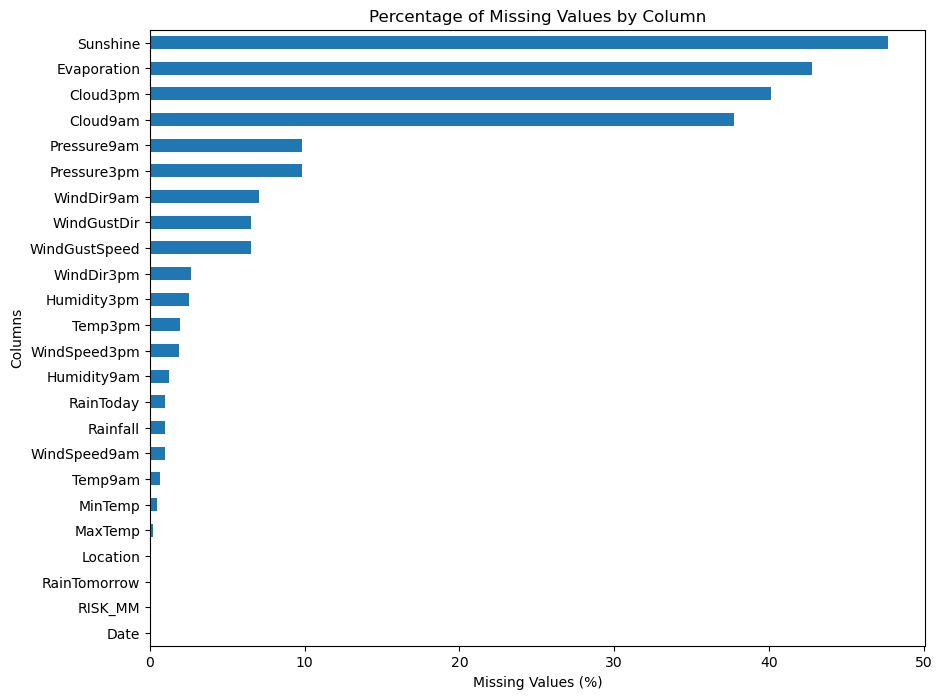

In [8]:
missing_percentage.sort_values().plot(kind='barh',figsize=(10, 8))
plt.xlabel('Missing Values (%)')
plt.ylabel('Columns')
plt.title('Percentage of Missing Values by Column')
plt.show()

### 3.4 Investigating Location Based Missingness

To determine whether missing observations are randomly distributed or associated with particular weather stations, the percentage of missing Sunshine measurements is calculated separately for each location.

The dataset is grouped by `Location`, and a lambda function calculates the proportion of missing Sunshine observations within each group.

**Interpretation:** The results reveal substantial differences between locations. Several stations have 100% missing Sunshine measurements, while others have almost complete records.

This suggests that missingness is associated with station location or reporting coverage rather than being uniformly distributed across the dataset.

Consequently, replacing every missing Sunshine value with a single overall average may not adequately represent differences between weather stations.

In [9]:
df.groupby('Location')['Sunshine'].apply(lambda x: x.isna().mean() * 100).sort_values(ascending=False)

Location
Newcastle           100.000000
Walpole             100.000000
NorahHead           100.000000
Penrith             100.000000
Richmond            100.000000
SalmonGums          100.000000
Launceston          100.000000
Katherine           100.000000
Tuggeranong         100.000000
GoldCoast           100.000000
Uluru               100.000000
Nhil                100.000000
MountGinini         100.000000
Witchcliffe         100.000000
Bendigo             100.000000
Ballarat            100.000000
BadgerysCreek       100.000000
Wollongong          100.000000
Albury              100.000000
Cobar                81.593039
Canberra             55.763604
CoffsHarbour         49.508974
Williamtown          47.081864
Adelaide             45.048544
Sale                 39.400000
Woomera              33.010033
Moree                28.065872
AliceSprings         16.859122
Albany               16.777188
Dartmoor             15.018688
Portland             14.719626
MountGambier         14.290429

### 3.5 Comparing Missingness Across Weather Stations

The missing value analysis based on location is extended to the four variables with the highest overall missing percentages: Sunshine, Evaporation, Cloud9am and Cloud3pm.

For each location, the percentage of missing observations is calculated independently for these variables.

**Interpretation:** The results show that missingness varies considerably between weather stations. Some locations have complete records for particular variables, whereas others have no available measurements.

This pattern indicates that data availability is not consistent across stations and variables.

The findings support evaluating missingness at both the column and location levels before selecting a cleaning strategy. 

In [10]:
columns = ['Sunshine', 'Evaporation', 'Cloud9am', 'Cloud3pm']
missing_by_location = (df.groupby('Location')[columns].apply(lambda x: x.isna().mean() * 100).round(2))
missing_by_location

,Sunshine,Evaporation,Cloud9am,Cloud3pm
Location,,,,
Adelaide,45.05,46.63,100.00,100.00
Albany,16.78,9.28,1.16,23.04
Albury,100.00,100.00,57.42,53.01
AliceSprings,16.86,6.96,10.95,11.81
BadgerysCreek,100.00,100.00,100.00,100.00
Ballarat,100.00,100.00,17.97,34.38
Bendigo,100.00,60.94,31.77,25.28
Brisbane,1.52,0.60,0.03,0.06
Cairns,14.26,11.41,6.19,6.89


### 3.6 Identifying Variables with Complete Missingness at Individual Stations

Following the missing value analysis based on location, an additional assessment was conducted to determine how many weather stations had no recorded observations for each of the four highly incomplete variables.

The analysis identifies locations where 100% of the observations are missing for a particular variable.

**Interpretation:**

These findings demonstrate that missing observations are concentrated at particular weather stations. For these locations, specific station statistical imputation cannot be performed because no valid measurements are available from which to calculate a mean or median.

This finding provides further justification for considering the removal of these four variables rather than relying on extensive imputation.

In [11]:
(missing_by_location == 100).sum()

Sunshine       19
Evaporation    16
Cloud9am       12
Cloud3pm       12
dtype: int64

### 3.7 Row Level Missing Value Analysis

In addition to examining missing values by column and location, the dataset was analysed at the observation level to determine how many weather records contained incomplete information.

A temporary variable, `missing_count`, was created to calculate the total number of missing values in each row. The distribution of these counts was then examined to understand the extent of incomplete observations.



In [12]:
# Missing values in each row
df['missing_count'] = df.isna().sum(axis=1)

# Distribution
df['missing_count'].value_counts().sort_index()
(df['missing_count'] > 0).mean() * 100

60.32153481535659

**Results:**

Approximately **60.32% of observations contain at least one missing value**.

**Interpretation:**

This indicates that missing data affects a substantial proportion of the dataset. Removing every observation containing a missing value would result in considerable data loss.
Therefore, a more selective cleaning strategy is required, combining the removal of highly incomplete variables with appropriate treatment of missing values in the remaining columns.
The temporary `missing_count` variable is used only for diagnostic purposes and is not intended to form part of the final dataset.


### 3.8 Evaluating the Removal of Highly Incomplete Variables

Based on the previous missing value investigations, four variables were identified as having particularly high levels of missingness: Sunshine, Evaporation, Cloud9am and Cloud3pm.

To evaluate the effect of removing these variables, a temporary dataset was created without the four columns. The proportion of observations containing at least one missing value was then compared with the original dataset.



In [13]:
# Removing temporary diagnostic column
df = df.drop(columns=['missing_count'], errors='ignore')

# Creating a temporary dataset
columns_to_drop = ['Sunshine','Evaporation', 'Cloud9am', 'Cloud3pm']
df_temp = df.drop(columns=columns_to_drop)

# Comparing incomplete rows
print("Original dataset:")
print(df.isna().any(axis=1).mean() * 100)

print("After removing four columns:")
print(df_temp.isna().any(axis=1).mean() * 100)

Original dataset:
60.32153481535659
After removing four columns:
20.583291723221254


**Results:**

- Original dataset: 60.32% of observations contained missing values.
- After removing the four variables: 20.58% of observations contained missing values.

**Interpretation:**

Removing these four variables reduced the proportion of incomplete observations by approximately **39.74 percentage points**.

This represents a substantial improvement in dataset completeness without removing any observations at this stage.

Although the removed variables may contain useful meteorological information, their extensive missingness and inconsistent availability across locations would make reliable imputation challenging.

Therefore, the analysis proceeds using the reduced dataset, while acknowledging the potential loss of information associated with removing these variables.

### 3.9 Creating a Working Dataset for Cleaning

Following the removal of the four highly incomplete variables, a separate working dataset was created using the Pandas `copy()` function.

This approach preserves the original dataset while allowing subsequent cleaning operations to be performed independently.

The dimensions of the original and working datasets are compared to confirm that only the intended columns have been removed.


In [14]:
# Creating a working copy
df_clean = df_temp.copy()

# Checking dimensions
print("Original shape:", df.shape)
print("Working shape:", df_clean.shape)

Original shape: (142193, 24)
Working shape: (142193, 20)



At this stage, the number of observations remains unchanged, while the number of variables is reduced from 24 to 20.
The resulting `df_clean` DataFrame is used for the remaining data cleaning operations.

### 3.10 Identifying Categorical Variables

After preparing the working dataset, the next step was to identify columns containing categorical or text based information.

The Pandas `select_dtypes()` function was used to retrieve columns stored with the `object` data type.

These include observation dates, weather station locations, wind directions and rainfall classification variables.

Identifying categorical variables is important because they require different validation and missing value treatment methods from numerical measurements.

For example, categorical values can be examined for inconsistent labels, unexpected categories and missing observations, while numerical variables can be assessed using statistical measures such as the mean and median.

In [15]:
df_clean.select_dtypes(include=['object']).columns

Index(['Date', 'Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm',
       'RainToday', 'RainTomorrow'],
      dtype='object')

### 3.11 Examining Categorical Values and Consistency

The unique values within each categorical column were examined to identify potential inconsistencies, unexpected categories and missing observations.

The `unique()` function was applied to each categorical variable to display its distinct values.



In [16]:
categorical_columns = df_clean.select_dtypes(include=['object']).columns
for col in categorical_columns:
    print(f"\nColumn: {col}")
    print(df_clean[col].unique())


Column: Date
['2008-12-01' '2008-12-02' '2008-12-03' ... '2008-01-29' '2008-01-30'
 '2008-01-31']

Column: Location
['Albury' 'BadgerysCreek' 'Cobar' 'CoffsHarbour' 'Moree' 'Newcastle'
 'NorahHead' 'NorfolkIsland' 'Penrith' 'Richmond' 'Sydney' 'SydneyAirport'
 'WaggaWagga' 'Williamtown' 'Wollongong' 'Canberra' 'Tuggeranong'
 'MountGinini' 'Ballarat' 'Bendigo' 'Sale' 'MelbourneAirport' 'Melbourne'
 'Mildura' 'Nhil' 'Portland' 'Watsonia' 'Dartmoor' 'Brisbane' 'Cairns'
 'GoldCoast' 'Townsville' 'Adelaide' 'MountGambier' 'Nuriootpa' 'Woomera'
 'Albany' 'Witchcliffe' 'PearceRAAF' 'PerthAirport' 'Perth' 'SalmonGums'
 'Walpole' 'Hobart' 'Launceston' 'AliceSprings' 'Darwin' 'Katherine'
 'Uluru']

Column: WindGustDir
['W' 'WNW' 'WSW' 'NE' 'NNW' 'N' 'NNE' 'SW' 'ENE' 'SSE' 'S' 'NW' 'SE' 'ESE'
 nan 'E' 'SSW']

Column: WindDir9am
['W' 'NNW' 'SE' 'ENE' 'SW' 'SSE' 'S' 'NE' nan 'SSW' 'N' 'WSW' 'ESE' 'E'
 'NW' 'WNW' 'NNE']

Column: WindDir3pm
['WNW' 'WSW' 'E' 'NW' 'W' 'SSE' 'ESE' 'ENE' 'NNW' 'SSW' 'SW

**Observations:**

- `Location` contains the names of Australian weather stations.
- `WindGustDir`, `WindDir9am` and `WindDir3pm` contain compass directions.
- `RainToday` and `RainTomorrow` contain the categories Yes and No.
- `Date` is initially stored as a text variable.
- Some categorical variables contain missing values represented by `NaN`.

**Interpretation:**

The initial inspection did not reveal obvious inconsistencies in the categorical labels. However, further validation is required to confirm that wind directions belong to the recognised compass categories. Additionally, the Date column should be converted to an appropriate datetime format to support chronological analysis and feature extraction.

### 3.12 Converting the Date Column to Datetime

The Date column was initially stored using the `object` data type, meaning that Pandas treated the dates as text rather than chronological values.

To ensure appropriate data handling, the column was converted to the datetime data type using `pd.to_datetime()`.

The expected date format was specified as `YYYY-MM-DD`, and `errors='raise'` was used to ensure that invalid date formats would generate an error rather than being silently converted.

In [17]:
df_clean['Date'] = pd.to_datetime(df_clean['Date'], format='%Y-%m-%d', errors='raise')
df_clean['Date'].dtype

dtype('<M8[ns]')

**Interpretation:**

Converting dates to datetime enables chronological sorting, time series analysis, monthly aggregation and the extraction of additional date based features.

This transformation also supports subsequent feature engineering, where year, month, day and season variables are derived from the original observation dates.

### 3.13 Validating Wind Direction Categories

Wind direction measurements were validated against the 16 recognised compass directions to identify any invalid or inconsistent categorical values.

A predefined set of valid directions was created, and the three wind direction variables were examined:

- WindGustDir
- WindDir9am
- WindDir3pm

The validation excluded missing observations and checked whether every available wind direction belonged to the predefined set.



In [18]:
# Validating wind directions
valid_directions = {
    'N', 'NNE', 'NE', 'ENE',
    'E', 'ESE', 'SE', 'SSE',
    'S', 'SSW', 'SW', 'WSW',
    'W', 'WNW', 'NW', 'NNW'}
wind_columns = ['WindGustDir', 'WindDir9am', 'WindDir3pm']
for col in wind_columns:
    invalid = df_clean[df_clean[col].notna() & ~df_clean[col].isin(valid_directions) ]
    print(f"{col}: {len(invalid)} invalid values")

WindGustDir: 0 invalid values
WindDir9am: 0 invalid values
WindDir3pm: 0 invalid values


**Results:**

All three variables returned zero invalid categorical values.

**Interpretation:**

The results confirm that the recorded, non-missing wind direction values are consistent with the expected compass categories.

Therefore, no categorical label corrections are required for these variables. However, missing wind direction observations still require appropriate treatment during the subsequent imputation process.

### 3.14 Rainfall Classification and Class Imbalance

The categorical rainfall indicators `RainToday` and `RainTomorrow` were examined to assess their distributions, identify missing values and determine whether the classes were balanced.

The `value_counts()` function was used with `dropna=False` to include missing observations in the frequency counts.



In [19]:
rain_columns = ['RainToday', 'RainTomorrow']
for col in rain_columns:
    print('\n')
    print(df_clean[col].value_counts(dropna=False))



RainToday
No     109332
Yes     31455
NaN      1406
Name: count, dtype: int64


RainTomorrow
No     110316
Yes     31877
Name: count, dtype: int64


**Results:**

For `RainTomorrow`:

- No: 110,316 observations.
- Yes: 31,877 observations.

Approximately 77.6% of the observations belong to the No category, while 22.4% belong to the Yes category.

The `RainToday` variable also contains 1,406 missing observations.

**Interpretation:**

The results demonstrate a noticeable class imbalance, with substantially more observations indicating no rainfall on the following day.

This imbalance is important for potential predictive modelling because a classification model could favour the majority class and achieve relatively high accuracy while performing poorly at identifying rainy days.

If predictive modelling is undertaken, appropriate evaluation metrics and class-balancing strategies should be considered. However, class balancing is not applied at this stage because the current analysis focuses on data preparation and exploration.

### 3.15 Validating Rainfall Classification Against Recorded Measurements

To verify the consistency of the `RainToday` categorical variable, recorded rainfall measurements were compared across the Yes and No categories.

The dataset was grouped by `RainToday`, and descriptive statistics were calculated for the numerical `Rainfall` variable.



In [20]:
# Checking RainToday against measured rainfall
df_clean.groupby('RainToday')['Rainfall'].describe()

,count,mean,std,min,25%,50%,75%,max
RainToday,,,,,,,,
No,109332.0,0.075187,0.199058,0.0,0.0,0.0,0.0,1.0
Yes,31455.0,10.256732,15.495105,1.1,2.4,5.2,11.8,371.0


**Results:**

- Observations classified as No recorded rainfall values between 0.0 mm and 1.0 mm.
- Observations classified as Yes recorded rainfall values beginning at 1.1 mm, with a maximum of 371.0 mm.

**Interpretation:**

The results demonstrate a consistent relationship between measured rainfall and the corresponding rainfall classification.

Within the observed dataset, the classification follows a threshold of 1.0 mm:

- Rainfall ≤ 1.0 mm corresponds to RainToday = No.
- Rainfall > 1.0 mm corresponds to RainToday = Yes.

This relationship provides a useful validation check and may support the treatment of missing rainfall classifications where the corresponding rainfall measurement is available. However, missing observations should be investigated before applying any replacement strategy.

### 3.16 Investigating Missing Rainfall Classification Records

Following the validation of the relationship between `Rainfall` and `RainToday`, observations with missing rainfall classifications were examined in greater detail.

The dataset was filtered to identify records where `RainToday` contained a missing value. The corresponding date, location and recorded rainfall measurements were displayed to investigate whether the missing classifications could be reconstructed from the available information.



In [21]:
# Checking missing RainToday records
df_clean[df_clean['RainToday'].isna()][['Date', 'Location', 'Rainfall', 'RainToday']].head(15)

,Date,Location,Rainfall,RainToday
14,2008-12-16,Albury,NaN,NaN
282,2009-09-11,Albury,NaN,NaN
433,2010-02-10,Albury,NaN,NaN
434,2010-02-12,Albury,NaN,NaN
439,2010-02-18,Albury,NaN,NaN
447,2010-02-27,Albury,NaN,NaN
449,2010-03-02,Albury,NaN,NaN
457,2010-03-11,Albury,NaN,NaN
603,2010-08-05,Albury,NaN,NaN
974,2011-09-14,Albury,NaN,NaN


**Results and Interpretation:**

The displayed observations indicate that missing `RainToday` classifications are accompanied by missing `Rainfall` measurements.

This suggests that the missing classifications cannot be directly reconstructed using the rainfall threshold identified in the previous analysis.

Further investigation is therefore required to determine whether both variables share the same missing-value pattern throughout the dataset.

### 3.17 Validating the Relationship Between Missing Rainfall Variables

To investigate whether missing rainfall measurements and missing rainfall classifications occur together, the number of missing observations in `Rainfall` and `RainToday` was calculated separately.

A logical AND operation was then applied to identify observations where both variables were missing simultaneously.






In [22]:
# Checking missing values in both columns

print("Missing Rainfall:",df_clean['Rainfall'].isna().sum())
print("Missing RainToday:",df_clean['RainToday'].isna().sum())
print("Both missing:",(df_clean['Rainfall'].isna() & df_clean['RainToday'].isna()).sum())

Missing Rainfall: 1406
Missing RainToday: 1406
Both missing: 1406




**Interpretation:**

The results confirm that the two variables have identical missing value patterns.

Every observation with a missing `Rainfall` measurement also has a missing `RainToday` classification, and no additional missing observations occur independently in either variable.

Because the rainfall classification depends on the measured rainfall, these observations cannot be reliably reconstructed using the available rainfall information alone.

This finding supports considering the removal of the affected observations as a practical data cleaning strategy.


### 3.18 Investigating the Geographic Distribution of Missing Rainfall Data

Before removing observations with missing rainfall measurements, their distribution across weather station locations was examined.

The dataset was filtered to identify observations where `Rainfall` was missing, and the frequency of these observations was calculated for each location.



In [23]:
df_clean.loc[df_clean['Rainfall'].isna(),'Location'].value_counts()

Location
Williamtown      177
Melbourne        137
PearceRAAF       116
MountGinini       91
Adelaide          70
Moree             63
GoldCoast         56
Penrith           53
BadgerysCreek     51
Walpole           49
Richmond          45
NorahHead         41
Wollongong        40
Tuggeranong       39
Brisbane          29
Witchcliffe       28
Newcastle         26
Cairns            24
Albany            20
NorfolkIsland     20
Albury            20
Uluru             19
WaggaWagga        18
Canberra          16
Katherine         14
SalmonGums        14
CoffsHarbour      13
Portland          12
Ballarat          11
Watsonia           9
Sale               8
Launceston         8
MountGambier       8
Cobar              8
Sydney             6
AliceSprings       6
Nuriootpa          6
Woomera            6
Townsville         6
Hobart             5
SydneyAirport      4
Nhil               4
Bendigo            4
Dartmoor           4
Mildura            2
Name: count, dtype: int64

**Results:**

The highest numbers of missing rainfall observations were recorded at:

- Williamtown: 177 observations.
- Melbourne: 137 observations.
- PearceRAAF: 116 observations.
- MountGinini: 91 observations.
- Adelaide: 70 observations.

**Interpretation:**

Missing rainfall measurements occur across multiple Australian weather stations, although some locations contribute more missing records than others.

These differences suggest that missingness is not distributed uniformly across locations.

However, the absolute number of missing observations does not establish the proportion of missing data at each station, as locations may have different numbers of recorded observations.

This investigation provides additional context for evaluating the potential impact of removing incomplete rainfall records.

### 3.19 Removing Observations with Missing Rainfall Measurements

Following the investigation of missing rainfall records, observations containing missing `Rainfall` values were removed from the working dataset using the Pandas `dropna()` function.

This approach was selected because the affected observations also lacked the corresponding `RainToday` classifications, preventing direct reconstruction of the missing values from the available rainfall measurements.



In [24]:
# The number of rows before cleaning
rows_before = len(df_clean)

# Removing rows where Rainfall is missing
df_clean = df_clean.dropna(subset=['Rainfall']).copy()

# Comparing results
print("Rows before:", rows_before)
print("Rows after:", len(df_clean))
print("Rows removed:", rows_before - len(df_clean))

# Verifying missing values
print("\nMissing Rainfall:", df_clean['Rainfall'].isna().sum())
print("Missing RainToday:", df_clean['RainToday'].isna().sum())

Rows before: 142193
Rows after: 140787
Rows removed: 1406

Missing Rainfall: 0
Missing RainToday: 0


**Interpretation:**

The removal affected approximately 0.99% of the original observations.

This reduced the missing data problem while retaining more than 99% of the original records.

The resulting dataset contains complete rainfall measurements and rainfall classifications, allowing subsequent analysis to proceed without missing values in these two variables.

Nevertheless, removing incomplete observations may introduce bias if missingness is associated with particular weather stations, time periods or weather conditions. This limitation should be considered when interpreting the final results.

### 3.20 Reassessing Missing Values After Row Removal

Following the removal of incomplete rainfall observations, the dataset was reassessed to identify variables that still contained missing values.

The `isna()` function was used to calculate missing-value counts for each column, and the results were sorted in descending order.



In [25]:
# Remaining missing values
df_clean.isna().sum().sort_values(ascending=False)

Pressure3pm      13769
Pressure9am      13743
WindDir9am        9660
WindGustDir       9163
WindGustSpeed     9105
WindDir3pm        3670
Humidity3pm       3501
Temp3pm           2624
WindSpeed3pm      2531
Humidity9am       1517
WindSpeed9am      1055
Temp9am            656
MinTemp            468
MaxTemp            307
RISK_MM              0
RainToday            0
Date                 0
Location             0
Rainfall             0
RainTomorrow         0
dtype: int64

**Results and Interpretation:**

The analysis confirms that `Rainfall` and `RainToday` no longer contain missing observations.

However, missing values remain in several meteorological measurements, particularly atmospheric pressure, wind direction and wind gust speed.

The largest remaining missing value counts occur in `Pressure3pm`, `Pressure9am`, `WindDir9am`, `WindGustDir` and `WindGustSpeed`.

These findings indicate that further data cleaning is necessary.

Because the remaining variables include both numerical and categorical measurements, different imputation strategies will be required to address their missing values appropriately.

### 3.21 Assessing Location-Based Missingness in Numerical Variables

To determine an appropriate imputation strategy for the remaining numerical variables, missing-value percentages were calculated separately for each weather station.

Numerical columns were selected using `select_dtypes()`, excluding `RISK_MM` from the assessment.

The dataset was grouped by `Location`, and the proportion of missing observations was calculated for each numerical variable.



In [26]:
# Numerical columns
numerical_columns = df_clean.select_dtypes(include='number').columns.drop('RISK_MM')
# Missing percentages by location
missing_numeric = (df_clean.groupby('Location')[numerical_columns].apply(lambda x: x.isna().mean() * 100))
# Locations with 100% missing values
(missing_numeric == 100).sum().sort_values(ascending=False)

Pressure9am      4
Pressure3pm      4
WindGustSpeed    2
MinTemp          0
MaxTemp          0
Rainfall         0
WindSpeed9am     0
WindSpeed3pm     0
Humidity9am      0
Humidity3pm      0
Temp9am          0
Temp3pm          0
dtype: int64

**Results:**

- Pressure9am is entirely missing at four locations.
- Pressure3pm is entirely missing at four locations.
- WindGustSpeed is entirely missing at two locations.
- All other selected numerical variables contain at least some valid observations at every location.

**Interpretation:**

The results indicate that median imputation based on location is feasible for most numerical variables because valid measurements are available within each station.
However, some stations have no recorded pressure or wind gust speed measurements. For these cases, a station-specific median cannot be calculated.

Therefore, an additional fallback strategy is required to handle missing values at locations where an entire numerical variable is unavailable.

### 3.22 Applying Location Based Median Imputation to Morning Pressure

An initial imputation procedure was applied to the `Pressure9am` variable using the median atmospheric pressure recorded at each weather station.

The dataset was grouped by `Location`, and a lambda function was used to replace missing morning pressure measurements with the median of the available observations from the corresponding station.

**Methodology:**

Location based median imputation was selected to account for differences in typical atmospheric conditions between weather stations.

The median was preferred over the mean because it is less sensitive to unusually high or low observations.



In [27]:
df_clean['Pressure9am'] = (df_clean.groupby('Location')['Pressure9am'].transform(lambda x: x.fillna(x.median())))

**Interpretation:**

This method replaces missing pressure measurements at locations where valid historical observations are available.

However, the procedure cannot fill missing values at stations where all morning pressure measurements are unavailable, because their location-specific median remains undefined.

Therefore, this operation represents an initial imputation step rather than a complete solution to the missing-pressure problem.

A fallback method is required for locations with entirely missing measurements.

### 3.23 Identifying Weather Stations Requiring Alternative Imputation

Following the assessment of numerical missingness, the specific weather stations with entirely missing measurements were identified.

Three variables were selected for further investigation: `Pressure9am`, `Pressure3pm` and `WindGustSpeed`.

The previously calculated location based missing value percentages were used to identify stations where 100% of the observations were unavailable.



In [28]:
special_columns = ['Pressure9am','Pressure3pm','WindGustSpeed']
for col in special_columns:
    locations = missing_numeric.index[missing_numeric[col] == 100]
    print(f"\n{col}:")
    print(locations.tolist())


Pressure9am:
['MountGinini', 'Newcastle', 'Penrith', 'SalmonGums']

Pressure3pm:
['MountGinini', 'Newcastle', 'Penrith', 'SalmonGums']

WindGustSpeed:
['Albany', 'Newcastle']


**Results:**

Both morning and afternoon pressure measurements are entirely missing at MountGinini, Newcastle, Penrith and SalmonGums.

Wind gust speed measurements are entirely missing at Albany and Newcastle.

**Interpretation:**

The same four locations have no available measurements for either atmospheric pressure variable, suggesting a station level limitation in pressure data availability.

Newcastle also lacks wind gust speed measurements, while Albany has no recorded wind gust speed observations.

These findings demonstrate that location based median imputation alone is insufficient for the selected variables.

An alternative imputation approach is therefore necessary to address missing measurements at these stations.

### 3.24 Quantifying Observations Requiring Fallback Imputation

After identifying weather stations with entirely missing numerical measurements, the number of affected observations was calculated for each variable.

The dataset was filtered to include locations where the selected measurement was completely unavailable, and the number of records at each affected station was counted.



In [29]:
# Affected rows at each location

for col in special_columns:
    affected_locations = missing_numeric.index[missing_numeric[col] == 100]
    print(f"\n{col}")
    print(df_clean[df_clean['Location'].isin(affected_locations)]['Location'].value_counts())


Pressure9am
Location
SalmonGums     2941
Newcastle      2929
Penrith        2911
MountGinini    2816
Name: count, dtype: int64

Pressure3pm
Location
SalmonGums     2941
Newcastle      2929
Penrith        2911
MountGinini    2816
Name: count, dtype: int64

WindGustSpeed
Location
Albany       2996
Newcastle    2929
Name: count, dtype: int64


**Results:**

For both Pressure9am and Pressure3pm: A total of 11,597 observations are affected for each pressure variable.

For WindGustSpeed: A total of 5,925 observations are affected.

**Interpretation:**

The results indicate that a substantial number of observations cannot be treated using location-specific median imputation alone.

Approximately 8.24% of the working dataset belongs to stations without recorded atmospheric pressure measurements.

This highlights the importance of considering the scale of missingness before selecting an imputation method.

For the purposes of this analysis, an overall median fallback is considered as a practical approach, while acknowledging that estimated values may not fully represent local atmospheric conditions.

### 3.25 Comparing Atmospheric Pressure Measurements Across Locations

Before finalising the numerical imputation strategy, median atmospheric pressure measurements were compared across Australian weather stations.

The dataset was grouped by `Location`, and median values were calculated separately for morning and afternoon atmospheric pressure.

The results were rounded to two decimal places and sorted according to morning pressure.



In [30]:
# Median pressure measurements by location
pressure_summary = (df_clean.groupby('Location')[['Pressure9am', 'Pressure3pm']].median().round(2))
pressure_summary.sort_values('Pressure9am')

,Pressure9am,Pressure3pm
Location,,
Darwin,1012.20,1008.60
Katherine,1013.10,1008.60
Cairns,1014.70,1011.60
Hobart,1015.40,1013.90
Townsville,1015.60,1012.30
Launceston,1016.40,1014.30
AliceSprings,1016.70,1012.70
Uluru,1017.10,1013.20
Perth,1017.40,1015.10


**Results and Interpretation:**

The analysis demonstrates differences in typical atmospheric pressure measurements between locations.
For example, Darwin recorded a median morning pressure of approximately 1012.20 hPa, while Canberra recorded approximately 1018.90 hPa.
The comparison also confirms that several locations have no available pressure measurements, resulting in undefined median values.
These differences highlight a limitation of using a single overall median to replace missing pressure measurements across all locations.

### 3.26 Completing Numerical Missing Value Imputation

Following the investigation of missing numerical observations, a two stage imputation strategy was implemented to address the remaining missing values.
First, numerical variables were grouped by weather station location, and missing observations were replaced using the median value calculated from the corresponding location.
Second, any values that remained missing were replaced using the overall median of the relevant variable. This fallback was necessary for weather stations where an entire measurement variable was unavailable.
The `RISK_MM` variable was excluded from this imputation procedure.



In [31]:
# Numerical weather columns
numerical_columns = df_clean.select_dtypes(include='number').columns.drop('RISK_MM')
# Missing counts before imputation
missing_before = df_clean[numerical_columns].isna().sum()
# Location-based median + overall median fallback
for col in numerical_columns:

    location_median = df_clean.groupby('Location')[col].transform('median')
    df_clean[col] = df_clean[col].fillna(location_median)
    # Remaining missing values using overall median
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Verify remaining missing values
print(df_clean[numerical_columns].isna().sum())

MinTemp          0
MaxTemp          0
Rainfall         0
WindGustSpeed    0
WindSpeed9am     0
WindSpeed3pm     0
Humidity9am      0
Humidity3pm      0
Pressure9am      0
Pressure3pm      0
Temp9am          0
Temp3pm          0
dtype: int64


**Results and Interpretation:**

The verification results confirmed that all 12 selected numerical weather variables contained zero missing values after imputation.
The combined strategy retained observations from weather stations with incomplete measurement coverage while preserving location specific differences wherever sufficient data was available.
However, imputed measurements represent statistical estimates rather than actual recorded weather conditions. This limitation should be considered when interpreting subsequent results.

### 3.27 Evaluating Numerical Imputation Results

To evaluate the effectiveness of the numerical imputation process, missing-value counts recorded before and after the procedure were compared.

A summary table was created containing three measurements for each numerical variable:

- Missing Before: the number of missing observations before the current imputation procedure.
- Missing After: the number of missing observations remaining after imputation.
- Values Filled: the difference between the two counts.



In [32]:
# Comparing missing values before and after
missing_after = df_clean[numerical_columns].isna().sum()
imputation_summary = pd.DataFrame({'Missing Before': missing_before,'Missing After': missing_after,'Values Filled': missing_before - missing_after})
imputation_summary

,Missing Before,Missing After,Values Filled
MinTemp,468,0,468
MaxTemp,307,0,307
Rainfall,0,0,0
WindGustSpeed,9105,0,9105
WindSpeed9am,1055,0,1055
WindSpeed3pm,2531,0,2531
Humidity9am,1517,0,1517
Humidity3pm,3501,0,3501
Pressure9am,11597,0,11597
Pressure3pm,13769,0,13769


**Results and Interpretation:**

The comparison confirms that the numerical imputation procedure successfully eliminated the remaining missing values in the selected numerical variables.
This demonstrates that the combination of location based medians and an overall median fallback was sufficient to produce complete numerical data for subsequent analysis.
It is important to note that `Pressure9am` had already undergone an earlier location based imputation step. Consequently, the missing value count recorded for that variable represents its state immediately before the final imputation procedure, rather than its original missing value count.

### 3.28 Identifying Remaining Categorical Missing Values

After completing numerical imputation, the entire working dataset was examined again to identify any remaining missing observations.
The results were sorted in descending order to highlight variables requiring additional treatment.



In [33]:
df_clean.isna().sum().sort_values(ascending=False)

WindDir9am       9660
WindGustDir      9163
WindDir3pm       3670
Date                0
Humidity3pm         0
RISK_MM             0
RainToday           0
Temp3pm             0
Temp9am             0
Pressure3pm         0
Pressure9am         0
WindSpeed3pm        0
Humidity9am         0
Location            0
WindSpeed9am        0
WindGustSpeed       0
Rainfall            0
MaxTemp             0
MinTemp             0
RainTomorrow        0
dtype: int64

**Results:**

Only three categorical wind direction variables contained missing values:

- WindDir9am: 9,660 observations.
- WindGustDir: 9,163 observations.
- WindDir3pm: 3,670 observations.

All other variables contained zero missing values.

**Interpretation:**

The findings confirm that the numerical missing-value treatment was successful. However, missing observations remain in the categorical wind direction measurements.

Because wind directions represent compass categories rather than continuous numerical values, median imputation is not appropriate.

A mode based imputation strategy is therefore selected to replace missing categorical values using the most frequently occurring wind direction at each weather station.

### 3.29 Completing Categorical Missing-Value Imputation

Missing observations in the three wind direction variables were addressed using a two stage mode based imputation strategy.

The variables included:

- WindGustDir
- WindDir9am
- WindDir3pm

First, the most frequently occurring wind direction was calculated separately for each weather station. Missing observations were then replaced using the corresponding location-specific mode.

Where a station did not contain sufficient valid observations to determine a mode, the overall mode of the variable was used as a fallback.



In [34]:
# Wind direction columns
wind_columns = ['WindGustDir','WindDir9am','WindDir3pm']

# Missing values before imputation
categorical_missing_before = df_clean[wind_columns].isna().sum()

# Missing values using location mode
for col in wind_columns:

    # Most common direction at each location
    location_mode = df_clean.groupby('Location')[col].transform(lambda x: x.mode().iloc[0] if not x.mode().empty else None )
    df_clean[col] = df_clean[col].fillna(location_mode)
    overall_mode = df_clean[col].mode().iloc[0]
    df_clean[col] = df_clean[col].fillna(overall_mode)

# Results
df_clean[wind_columns].isna().sum()

WindGustDir    0
WindDir9am     0
WindDir3pm     0
dtype: int64

**Results and Interpretation:**

The verification results confirmed that all three wind direction variables contained zero missing values after imputation.

This approach maintains the categorical nature of wind direction measurements and accounts for station-level differences where possible.

However, the mode represents the most common observed category rather than the actual wind direction on a particular day. Therefore, the replacement values introduce some uncertainty into the cleaned dataset.

### 3.30 Verifying Dataset Completeness After Cleaning

Following numerical and categorical imputation, a final missing-value assessment was conducted to verify the completeness of the working dataset.

The total number of missing observations was calculated, the dataset dimensions were examined, and missing-value counts were checked individually for every column.



In [35]:
# Remaining missing values
print("Total missing values:", df_clean.isna().sum().sum())
# Checking dataset dimensions
print("Dataset shape:", df_clean.shape)
# Checking missing values by column
df_clean.isna().sum()

Total missing values: 0
Dataset shape: (140787, 20)


Date             0
Location         0
MinTemp          0
MaxTemp          0
Rainfall         0
WindGustDir      0
WindGustSpeed    0
WindDir9am       0
WindDir3pm       0
WindSpeed9am     0
WindSpeed3pm     0
Humidity9am      0
Humidity3pm      0
Pressure9am      0
Pressure3pm      0
Temp9am          0
Temp3pm          0
RainToday        0
RISK_MM          0
RainTomorrow     0
dtype: int64

**Results:**

- Final dataset dimensions: 140,787 rows and 20 columns.
- Total remaining missing values: 0.
- All columns contain complete observations.

**Interpretation:**

The results confirm that the selected data cleaning procedures successfully addressed all missing values in the working dataset.

The cleaned dataset retains a substantial number of historical weather observations and is suitable for subsequent exploratory analysis, correlation assessment, data merging and feature engineering.

Although the dataset is now complete, it contains imputed values that may influence statistical distributions and relationships. This limitation should be acknowledged when interpreting the analysis.

### 3.31 Exploring Correlations Between Numerical Weather Variables

Following the completion of missing value treatment, correlation analysis was conducted to investigate relationships between the numerical weather measurements.

A correlation matrix was calculated using the Pandas `corr()` function and visualised using a Seaborn heatmap.

The heatmap displays correlation coefficients ranging from -1 to +1:

- Values approaching +1 indicate strong positive linear relationships.
- Values approaching -1 indicate strong negative linear relationships.
- Values approaching 0 indicate weak or no linear relationships.

The `RISK_MM` variable was excluded because it contains information about future rainfall and could introduce data leakage into predictive analysis.



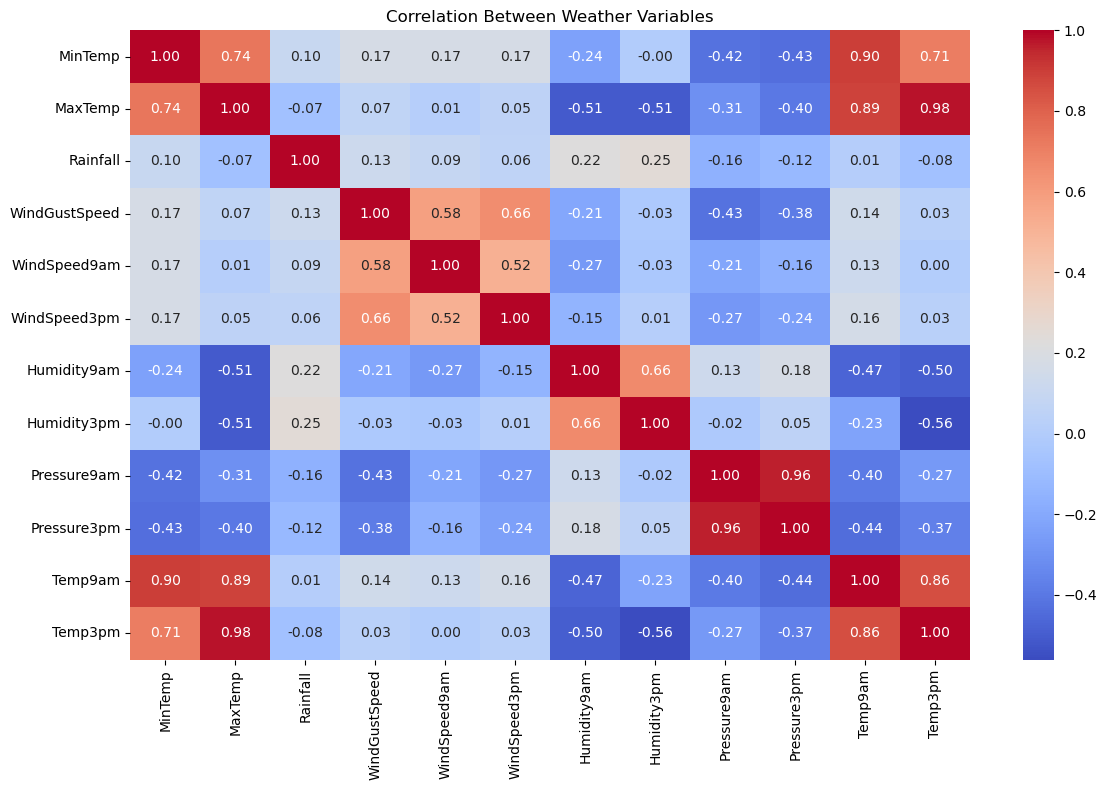

In [36]:
# Excluding RISK_MM because it contains future rainfall information
numeric_df = df_clean.select_dtypes(include='number').drop(columns=['RISK_MM'],errors='ignore')
# Calculating correlations
correlation_matrix = numeric_df.corr()
# Visualizing correlations
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Between Weather Variables')
plt.tight_layout()
plt.show()

**Interpretation:**

The heatmap reveals several strong positive relationships between temperature and atmospheric pressure measurements recorded at different times of the day.

These relationships suggest that certain variables contain overlapping information.

The correlation analysis provides a foundation for identifying potentially redundant variables and evaluating the dimensionality of the dataset.

However, correlation does not establish causation, and strongly correlated variables are not automatically removed without considering their analytical relevance.

### 3.32 Identifying Highly Correlated Features

To investigate potential redundancy among numerical variables, the absolute correlation matrix was examined to identify feature pairs with correlation coefficients greater than 0.90.

The upper triangular portion of the matrix was selected to avoid reporting duplicate variable pairs.



In [37]:
# Absolute correlation matrix
corr_matrix = numeric_df.corr().abs()
# Upper triangle to avoid duplicate pairs
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
# Strongly correlated pairs
high_corr = (upper.stack().loc[lambda x: x > 0.90].sort_values(ascending=False))
print(high_corr)

MaxTemp      Temp3pm        0.980689
Pressure9am  Pressure3pm    0.960058
MinTemp      Temp9am        0.901001
dtype: float64


**Results:**

Three strongly correlated pairs were identified:

- MaxTemp and Temp3pm: 0.980689.
- Pressure9am and Pressure3pm: 0.960058.
- MinTemp and Temp9am: 0.901001.

**Interpretation:**

The strongest relationship was observed between daily maximum temperature and afternoon temperature, indicating that these variables frequently follow similar patterns.

Morning and afternoon atmospheric pressure measurements also demonstrate a strong positive relationship, while minimum temperature and morning temperature show substantial correlation.

These findings indicate potential redundancy in the numerical features.

However, the variables were retained because measurements recorded at different times may provide useful information for weather analysis and subsequent feature engineering.

If predictive modelling is undertaken, additional feature-selection techniques could be applied to determine whether removing highly correlated variables improves model performance.

### 3.33 Final Data Quality and Integrity Validation

Before proceeding to the next stage of analysis, the cleaned dataset was subjected to a final series of data quality checks.

The validation assessed dataset dimensions, missing observations, fully duplicated records and duplicate combinations of Date and Location.

The Date–Location combination was examined because it represents the observation date and weather station associated with each record.



In [38]:
print("Dataset shape:", df_clean.shape)
print("Total missing values:")
print(df_clean.isna().sum().sum())
print("Duplicate rows:")
print(df_clean.duplicated().sum())
print("Duplicate Date Location records:")
print(df_clean.duplicated(subset=['Date', 'Location']).sum())

Dataset shape: (140787, 20)
Total missing values:
0
Duplicate rows:
0
Duplicate Date Location records:
0


**Interpretation:**

The results confirm that the cleaned dataset contains no missing observations or duplicated records under the selected validation criteria.

The absence of duplicate Date Location combinations also indicates that each retained station date combination is unique.

These checks provide confidence in the structural consistency of the cleaned dataset before proceeding to data merging and feature engineering.

However, they do not independently establish that every weather measurement is physically accurate.

### 3.34 Exporting the Cleaned Weather Dataset

Following the successful completion of data cleaning and integrity validation, the processed dataset was exported to a new CSV file.

The Pandas `to_csv()` function was used to save the cleaned DataFrame as `weatherAUS_cleaned.csv`.

The `index=False` parameter was specified to prevent the DataFrame index from being included as an additional column in the exported file.



In [39]:
# Save cleaned dataset
df_clean.to_csv('weatherAUS_cleaned.csv', index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


**Results and Interpretation:**

The notebook confirmed that the cleaned dataset was saved successfully.
Exporting the processed dataset creates a reusable data source for subsequent analysis and reduces the need to repeat the cleaning procedures.
It also preserves the original source dataset separately from the cleaned version, supporting reproducibility and clearer documentation of the data preparation process.

## 4. Data Merging

### 4.1 Creating the Temperature and Rainfall Dataset

To demonstrate data merging using Pandas, the cleaned weather dataset was divided into smaller datasets containing related meteorological variables.

The first dataset, `df_temperature`, was created by selecting nine columns associated with temperature, rainfall and observation identification.

The selected variables include:

- Date and Location, which identify individual weather observations.
- MinTemp, MaxTemp, Temp9am and Temp3pm, which represent temperature measurements.
- Rainfall, RainToday and RainTomorrow, which describe rainfall measurements and classifications.

The `copy()` function was used to create an independent DataFrame without modifying the cleaned source dataset.



In [40]:
df_temperature = df_clean[['Date','Location','MinTemp','MaxTemp','Temp9am','Temp3pm','Rainfall','RainToday','RainTomorrow']].copy()
df_temperature.head()

,Date,Location,MinTemp,MaxTemp,Temp9am,Temp3pm,Rainfall,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,16.9,21.8,0.6,No,No
1,2008-12-02,Albury,7.4,25.1,17.2,24.3,0.0,No,No
2,2008-12-03,Albury,12.9,25.7,21.0,23.2,0.0,No,No
3,2008-12-04,Albury,9.2,28.0,18.1,26.5,0.0,No,No
4,2008-12-05,Albury,17.5,32.3,17.8,29.7,1.0,No,No


**Interpretation:**

This operation prepares a temperature and rainfall dataset that can subsequently be combined with a separate dataset containing atmospheric measurements.

Date and Location are retained as common identifiers to support merging observations from the same weather station and date.

The approach demonstrates how related information can be separated into logical datasets and subsequently recombined using common keys.

### 4.2 Creating the Atmospheric Conditions Dataset

The second dataset, `df_atmosphere`, was created by selecting variables related to wind conditions, humidity and atmospheric pressure from the cleaned weather dataset.

The selected variables include wind gust direction, wind gust speed, morning and afternoon wind direction, wind speed, humidity and atmospheric pressure.

The Date and Location columns were retained as common identifiers to enable the atmospheric dataset to be merged with the previously created temperature and rainfall dataset.

The Pandas `copy()` function was used to create an independent DataFrame without modifying the cleaned source dataset.



In [41]:
df_atmosphere = df_clean[['Date','Location','WindGustDir','WindGustSpeed','WindDir9am','WindDir3pm','WindSpeed9am','WindSpeed3pm','Humidity9am','Humidity3pm','Pressure9am','Pressure3pm']].copy()
df_atmosphere.head()

,Date,Location,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm
0,2008-12-01,Albury,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1
1,2008-12-02,Albury,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8
2,2008-12-03,Albury,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7
3,2008-12-04,Albury,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8
4,2008-12-05,Albury,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0


**Interpretation:**

Separating the weather variables into two logical datasets demonstrates how related information can be organised independently before being combined through common identifiers.
The atmospheric dataset contains 12 columns, including the two merging keys, Date and Location.
This structure allows the analysis to demonstrate dataset integration using Pandas while preserving the relationships between measurements recorded at the same weather station on the same date.

### 4.3 Validating Dataset Dimensions and Unique Merge Keys

Before merging the temperature and atmospheric datasets, their dimensions and merging keys were examined to confirm their suitability for integration.

The `shape` attribute was used to determine the number of observations and variables in each dataset.

The `duplicated()` function was then applied to the combined Date and Location columns to identify any repeated keys.



In [42]:
print("Temperature dataset:", df_temperature.shape)
print("Atmosphere dataset:", df_atmosphere.shape)
print("\nTemperature duplicate keys:",df_temperature.duplicated(subset=['Date', 'Location'] ).sum())
print("Atmosphere duplicate keys:",df_atmosphere.duplicated(subset=['Date', 'Location']).sum())

Temperature dataset: (140787, 9)
Atmosphere dataset: (140787, 12)

Temperature duplicate keys: 0
Atmosphere duplicate keys: 0


**Results:**

- Temperature dataset: 140,787 observations and 9 columns.
- Atmospheric dataset: 140,787 observations and 12 columns.
- Duplicate Date Location keys in the temperature dataset: 0.
- Duplicate Date Location keys in the atmospheric dataset: 0.

**Interpretation:**

Both datasets contain the same number of observations, and neither contains duplicate Date Location combinations.
These results indicate that each observation can be uniquely identified by its date and weather station location.
The absence of duplicate merging keys supports a one to one relationship between the datasets, reducing the risk of unintended row multiplication during merging.
However, equal row counts alone do not guarantee that the same keys exist in both datasets. This is verified during the subsequent merge validation.

### 4.4 Merging the Temperature and Atmospheric Datasets

The temperature and atmospheric datasets were combined using the Pandas `merge()` function.

An inner join was performed using Date and Location as the common merging keys.

The `how='inner'` parameter ensures that only observations with matching Date Location combinations in both datasets are retained.

Additionally, `validate='one_to_one'` was specified to verify that each merging key occurs no more than once in either dataset.



In [43]:
df_merged = pd.merge(df_temperature, df_atmosphere, on=['Date', 'Location'],how='inner',validate='one_to_one')
df_merged.head()

,Date,Location,MinTemp,MaxTemp,Temp9am,Temp3pm,Rainfall,RainToday,RainTomorrow,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm
0,2008-12-01,Albury,13.4,22.9,16.9,21.8,0.6,No,No,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1
1,2008-12-02,Albury,7.4,25.1,17.2,24.3,0.0,No,No,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8
2,2008-12-03,Albury,12.9,25.7,21.0,23.2,0.0,No,No,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7
3,2008-12-04,Albury,9.2,28.0,18.1,26.5,0.0,No,No,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8
4,2008-12-05,Albury,17.5,32.3,17.8,29.7,1.0,No,No,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0


**Interpretation:**

The merging operation successfully combines temperature, rainfall, wind, humidity and atmospheric pressure measurements into a single DataFrame.
The resulting dataset contains all the selected weather variables associated with each matching station-date observation.
The one to one validation provides an additional safeguard against unexpected duplication caused by repeated merging keys.
This operation demonstrates how datasets containing related information can be integrated while maintaining a consistent observational structure.

### 4.5 Validating the Merged Dataset

Following the inner join, several validation checks were performed to confirm the structural integrity of the merged dataset.

The number of observations in the original cleaned dataset was compared with the merged dataset. The merged dataset dimensions, duplicate Date–Location keys and total missing values were also examined.



In [44]:
print("Original rows:", len(df_clean))
print("Merged rows:", len(df_merged))
print("Merged shape:", df_merged.shape)
print("Duplicate keys:",df_merged.duplicated(subset=['Date', 'Location']).sum())
print("Total missing values:", df_merged.isna().sum().sum())

Original rows: 140787
Merged rows: 140787
Merged shape: (140787, 19)
Duplicate keys: 0
Total missing values: 0


**Interpretation:**

The results confirm that the merging operation retained all 140,787 observations without introducing duplicate keys or missing values.
The merged dataset contains 19 variables because Date and Location were shared between the two source datasets and were included only once in the final output.
The successful validation indicates that the selected inner join preserved the structural completeness of the cleaned weather observations.


### 4.6 Simulating Missing Records for Join Comparison

To demonstrate how different merging methods behave when datasets contain unmatched observations, a temporary atmospheric dataset was created.

The first 100 observations were excluded from `df_atmosphere` using the Pandas `iloc` function.

This produced a test dataset containing fewer records than the original atmospheric dataset.



In [45]:
# Creating a temporary atmosphere dataset
df_atmosphere_test = df_atmosphere.iloc[100:].copy()
print("Temperature rows:", len(df_temperature))
print("Atmosphere test rows:", len(df_atmosphere_test))

Temperature rows: 140787
Atmosphere test rows: 140687


**Interpretation:**

The temporary dataset creates a controlled scenario in which 100 Date Location combinations exist in the temperature dataset but are absent from the atmospheric dataset.
This allows different join operations to be compared and demonstrates how unmatched records influence the resulting dataset.
The original atmospheric dataset remains unchanged because the modification was applied to a separate copy.
The simulated missing records are used only for demonstrating merging behaviour and are not part of the final merged dataset.

### 4.7 Comparing Inner, Left, Right and Outer Joins

To investigate how different merging strategies handle unmatched observations, four join types were applied to the temperature dataset and the temporary atmospheric dataset.

The join operations included inner, left, right and outer joins, using Date and Location as the common merging keys.



In [46]:
# Different join types
for join_type in ['inner', 'left', 'right', 'outer']:
    result = pd.merge(df_temperature,df_atmosphere_test, on=['Date', 'Location'],how=join_type,validate='one_to_one')
    print(f"{join_type}: {result.shape}")

inner: (140687, 19)
left: (140787, 19)
right: (140687, 19)
outer: (140787, 19)


**Interpretation:**

The inner join retained only observations with matching keys in both datasets, excluding the 100 records missing from the temporary atmospheric dataset.
The left join retained all observations from the temperature dataset, including the 100 unmatched records.
The right join retained all observations from the temporary atmospheric dataset, resulting in 140,687 records.
The outer join retained every unique key from both datasets. Because the temporary atmospheric dataset contained only a subset of the temperature dataset's keys, its row count was identical to the left join.
This comparison demonstrates how join selection influences record retention and potential missing values in the merged results.

### 4.8 Identifying Matched and Unmatched Observations

An outer join was performed using the temporary atmospheric dataset to investigate the origin of records in the merged result.

The `indicator=True` parameter was used to create an additional column named `_merge`, identifying whether each observation originated from both datasets, the left dataset only, or the right dataset only.



In [47]:
merge_check = pd.merge(df_temperature, df_atmosphere_test, on=['Date', 'Location'], how='outer', indicator=True, validate='one_to_one')
merge_check['_merge'].value_counts()

_merge
both          140687
left_only        100
right_only         0
Name: count, dtype: int64

**Interpretation:**

The results confirm that 140,687 observations have matching Date Location combinations in both datasets.
The 100 left only observations correspond to the records deliberately excluded from the temporary atmospheric dataset.
No right only observations were identified because all records in the temporary atmospheric dataset were already present in the temperature dataset.
This validation demonstrates that the different join results are consistent with the simulated missing record scenario.
It also highlights the usefulness of merge indicators for identifying unmatched records and investigating data integration issues.

### 4.9 Verifying Data Integrity After Merging

Following the successful completion of the merging operations, a detailed comparison was performed to verify that the merged dataset preserved the original weather measurements.

The columns included in the merged dataset were selected from the original cleaned dataset.

Both datasets were then sorted by Date and Location, and their indexes were reset to ensure consistent row alignment.

The Pandas `assert_frame_equal()` function was used to compare the resulting DataFrames.



In [48]:
# Columns included in the merged dataset
columns_to_compare = df_merged.columns.tolist()
# Sorting both datasets by Date and Location
original_sorted = (df_clean[columns_to_compare].sort_values(['Date', 'Location']).reset_index(drop=True))
merged_sorted = (df_merged.sort_values(['Date', 'Location']).reset_index(drop=True))
# Data integrity
pd.testing.assert_frame_equal(original_sorted, merged_sorted)
print("Merge validation passed!")
print("All merged values match the original dataset.")

Merge validation passed!
All merged values match the original dataset.


**Interpretation:**

The successful comparison confirms that the merged dataset contains the same values as the corresponding columns in the original cleaned dataset.
This demonstrates that the merging procedure did not introduce unintended changes to the retained measurements.
Combined with the earlier row count, duplicate key and missing value checks, the result provides strong evidence that the merging process preserved data integrity.
The validation applies to the 19 variables included in the merged dataset.

### 4.10 Exporting the Validated Merged Dataset

After completing the merging operations and confirming data integrity, the merged weather dataset was exported to a CSV file.

The Pandas `to_csv()` function was used to save the combined dataset as `weatherAUS_merged.csv`.

The `index=False` parameter was specified to exclude the DataFrame index from the exported file.



In [49]:
df_merged.to_csv('weatherAUS_merged.csv', index=False)
print("Merged dataset saved successfully!")

Merged dataset saved successfully!


**Results and Interpretation:**

The notebook confirmed that the merged dataset was saved successfully.
The exported dataset contains 140,787 observations and 19 variables, combining temperature, rainfall, wind, humidity and atmospheric pressure information.
Saving the validated dataset provides a reusable input for subsequent feature engineering and analysis.
It also creates a clear separation between the cleaned dataset and the merged dataset, supporting reproducibility and documenting the stages of the data-processing workflow.

## 5. Feature Engineering

### 5.1 Preparing the Dataset for Feature Engineering

Following the successful merging and validation of the weather datasets, a separate DataFrame was created for feature engineering.

Feature engineering involves deriving additional variables from existing observations to support more detailed analysis and reveal relationships that may not be immediately apparent in the original data.

The Pandas `copy()` function was used to create `df_features` from the validated merged dataset.

This ensures that new features can be introduced without modifying the original merged DataFrame.



In [50]:
# Creating a separate dataset for feature engineering
df_features = df_merged.copy()
# Checking dataset dimensions
print("Original shape:", df_merged.shape)
print("Feature dataset shape:", df_features.shape)

Original shape: (140787, 19)
Feature dataset shape: (140787, 19)


**Interpretation:**

The results confirm that the feature engineering dataset initially contains the same observations and variables as the merged dataset.
This provides a consistent starting point for creating additional features from date, temperature, humidity, atmospheric pressure and wind speed measurements.
The subsequent analysis will demonstrate how existing weather observations can be transformed into additional variables to support exploratory analysis and data preprocessing.

### 5.2 Extracting Date-Based Features

To support time-based weather analysis, additional features were extracted from the existing Date column.

The Date column was converted to the Pandas datetime format, allowing individual components to be accessed using the `.dt` accessor.

Four new variables were created:

- **Year:** Identifies the calendar year of each observation.
- **Month:** Identifies the month, ranging from 1 to 12.
- **Day:** Identifies the day of the month.
- **DayOfWeek:** Represents the day of the week, where Monday is 0 and Sunday is 6.



In [51]:
# Converting Date to datetime
df_features['Date'] = pd.to_datetime(df_features['Date'])
# Extracting date components
df_features['Year'] = df_features['Date'].dt.year
df_features['Month'] = df_features['Date'].dt.month
df_features['Day'] = df_features['Date'].dt.day
df_features['DayOfWeek'] = df_features['Date'].dt.dayofweek

# Viewing results
df_features[['Date', 'Year', 'Month', 'Day', 'DayOfWeek']].head(10)

,Date,Year,Month,Day,DayOfWeek
0,2008-12-01,2008,12,1,0
1,2008-12-02,2008,12,2,1
2,2008-12-03,2008,12,3,2
3,2008-12-04,2008,12,4,3
4,2008-12-05,2008,12,5,4
5,2008-12-06,2008,12,6,5
6,2008-12-07,2008,12,7,6
7,2008-12-08,2008,12,8,0
8,2008-12-09,2008,12,9,1
9,2008-12-10,2008,12,10,2


**Results and Interpretation:**

The first ten observations demonstrate that the date components were extracted successfully. For example, 1 December 2008 was assigned Year = 2008, Month = 12, Day = 1 and DayOfWeek = 0.

These additional features allow observations to be grouped and compared across different time periods.

Month and Year are particularly useful for investigating seasonal patterns and changes in weather measurements over time.

### 5.3 Creating a Seasonal Classification Feature

A new categorical feature named `Season` was created to classify each weather observation according to the Australian seasonal calendar.

A custom Python function, `get_season()`, was developed to assign a season based on the month of observation.

The following seasonal definitions were applied:

- Summer: December, January and February.
- Autumn: March, April and May.
- Winter: June, July and August.
- Spring: September, October and November.

The function was applied to the Month column using Pandas' `apply()` method.



In [52]:
# Defining Australian seasons
def get_season(month):
    if month in [12, 1, 2]:
        return 'Summer'
    elif month in [3, 4, 5]:
        return 'Autumn'
    elif month in [6, 7, 8]:
        return 'Winter'
    else:
        return 'Spring'
# Applying function
df_features['Season'] = df_features['Month'].apply(get_season)
# Results
df_features[['Date', 'Month', 'Season']].head(10)

,Date,Month,Season
0,2008-12-01,12,Summer
1,2008-12-02,12,Summer
2,2008-12-03,12,Summer
3,2008-12-04,12,Summer
4,2008-12-05,12,Summer
5,2008-12-06,12,Summer
6,2008-12-07,12,Summer
7,2008-12-08,12,Summer
8,2008-12-09,12,Summer
9,2008-12-10,12,Summer


**Results and Interpretation:**

The output confirms that observations recorded in December 2008 were correctly classified as Summer.
This feature enables weather observations to be grouped into meaningful seasonal categories without repeatedly evaluating individual months.
Seasonal classification is particularly relevant to Australian weather analysis because temperature, rainfall and humidity patterns vary across the year and between geographic locations.
The classification uses meteorological seasons rather than astronomical season boundaries.

### 5.4 Creating Derived Meteorological Features

Four additional numerical features were created to describe differences between weather measurements recorded during the same day.

These features were calculated using arithmetic operations on existing numerical variables.



In [53]:
# Daily temperature range
df_features['TempRange'] = (df_features['MaxTemp'] - df_features['MinTemp'])
# Humidity change from morning to afternoon
df_features['HumidityChange'] = (df_features['Humidity3pm'] - df_features['Humidity9am'])
# Pressure change from morning to afternoon
df_features['PressureChange'] = (df_features['Pressure3pm'] - df_features['Pressure9am'])
# Wind speed change
df_features['WindSpeedChange'] = (df_features['WindSpeed3pm'] - df_features['WindSpeed9am'])
# Engineered features
df_features[['TempRange','HumidityChange','PressureChange','WindSpeedChange']].head(10)

,TempRange,HumidityChange,PressureChange,WindSpeedChange
0,9.5,-49.0,-0.6,4.0
1,17.7,-19.0,-2.8,18.0
2,12.8,-8.0,1.1,7.0
3,18.8,-29.0,-4.8,-2.0
4,14.8,-49.0,-4.8,13.0
5,15.1,-32.0,-3.8,5.0
6,10.7,-30.0,-1.4,4.0
7,19.0,-29.0,-3.3,11.0
8,22.2,-33.0,-5.3,21.0
9,17.0,-31.0,-1.3,-4.0


**Temperature Range (TempRange)** This feature represents the difference between the highest and lowest recorded temperatures.

**Humidity Change (HumidityChange)** Negative values indicate lower relative humidity in the afternoon compared with the morning.

**Pressure Change (PressureChange)** This feature describes the change in atmospheric pressure between morning and afternoon observations.

**Wind Speed Change (WindSpeedChange)** Positive values indicate higher afternoon wind speeds, while negative values indicate lower afternoon wind speeds.

**Interpretation:**

These engineered features provide additional information about daily weather variation that is not represented by individual measurements alone.
The resulting variables support further descriptive analysis, comparison and potential predictive modelling.

### 5.5 Evaluating Engineered Feature Distributions

Following the creation of additional date-based and meteorological variables, the dataset dimensions, missing values and descriptive statistics were examined.

The Pandas `describe()` function was applied to the four engineered numerical features to assess their distributions.



In [54]:
# Dataset dimensions
print("Dataset shape:", df_features.shape)
# Missing values
print("Missing values:", df_features.isna().sum().sum())
# Check feature engineering statistics
df_features[['TempRange','HumidityChange','PressureChange','WindSpeedChange']].describe()

Dataset shape: (140787, 28)
Missing values: 0


,TempRange,HumidityChange,PressureChange,WindSpeedChange
count,140787.000000,140787.000000,140787.000000,140787.000000
mean,11.046680,-17.387614,-2.394861,4.584884
std,4.958659,16.297920,1.899668,8.676582
min,-3.100000,-91.000000,-27.100000,-123.000000
25%,7.200000,-28.000000,-3.600000,0.000000
50%,10.500000,-17.000000,-2.400000,4.000000
75%,14.500000,-6.000000,-1.500000,10.000000
max,32.000000,91.000000,21.800000,78.000000


**Results:**

- Dataset dimensions: 140,787 rows and 28 columns.
- Total missing values: 0.
- Mean temperature range: approximately 11.05°C.
- Mean humidity change: approximately -17.39 percentage points.
- Mean pressure change: approximately -2.39 hPa.
- Mean wind speed change: approximately 4.58 km/h.

**Interpretation:**

The results confirm that eight additional features were successfully created without introducing missing observations.
The negative average humidity change indicates that afternoon relative humidity was generally lower than morning humidity across the dataset.
The negative average pressure change indicates that afternoon atmospheric pressure was generally lower than morning pressure.
However, the minimum temperature range was -3.1°C. Because the daily maximum temperature should not be lower than the daily minimum temperature, this result indicates a potential data inconsistency requiring further investigation.
The next stage examines these observations before proceeding with feature scaling.

### 5.6 Identifying Inconsistent Temperature Measurements

The descriptive statistical analysis identified negative values in the newly created `TempRange` feature.

To investigate this issue, the dataset was filtered to identify observations where the calculated temperature range was less than zero.



In [55]:
# Negative temperature ranges
negative_temp = df_features[df_features['TempRange'] < 0]
print("Negative temperature ranges:", len(negative_temp))
# Affected observations
negative_temp[['Date','Location','MinTemp','MaxTemp','TempRange']].head(20)

Negative temperature ranges: 3


,Date,Location,MinTemp,MaxTemp,TempRange
17163,2016-06-27,Newcastle,13.8,13.0,-0.8
17431,2017-03-30,Newcastle,23.8,23.5,-0.3
50386,2009-08-30,MountGinini,3.2,0.1,-3.1


**Results:**

Three observations were identified:

- Newcastle, 27 June 2016: -0.8°C.
- Newcastle, 30 March 2017: -0.3°C.
- MountGinini, 30 August 2009: -3.1°C.

**Interpretation:**

A negative daily temperature range indicates that the recorded or estimated minimum temperature exceeds the maximum temperature.
This is inconsistant with the definitions of daily minimum and maximum temperature.
The affected observations may have resulted from the earlier missing-value imputation procedure, which replaced missing measurements using statistical estimates without explicitly enforcing the relationship between minimum and maximum temperatures.
Before correcting the values, the original dataset must be examined to determine whether the inconsistency existed in the source measurements or was introduced during data preparation.

### 5.7 Investigating the Source of Temperature Inconsistencies

To determine the cause of the negative temperature ranges, the three affected observations were compared with their corresponding records in the original dataset.

The Date and Location columns were used as matching keys to retrieve the original minimum and maximum temperature measurements.



In [56]:
# Identifying the three affected observations
affected_keys = negative_temp[['Date', 'Location']].copy()
# Converting original Date column for matching
df_original_check = df.copy()
df_original_check['Date'] = pd.to_datetime(df_original_check['Date'])
# Retrieving original temperature measurements
original_temperatures = pd.merge(affected_keys,
    df_original_check[['Date', 'Location', 'MinTemp', 'MaxTemp']], on=['Date', 'Location'], how='left', validate='one_to_one')
original_temperatures

,Date,Location,MinTemp,MaxTemp
0,2016-06-27,Newcastle,NaN,13.0
1,2017-03-30,Newcastle,23.8,NaN
2,2009-08-30,MountGinini,NaN,0.1


**Results:**

The investigation revealed that each affected observation originally contained one missing temperature measurement.

For two observations, the original minimum temperature was missing. For the remaining observation, the original maximum temperature was missing.

**Interpretation:**

These findings indicate that the negative temperature ranges were introduced during the missing-value imputation process rather than being present as conflicting recorded measurements in the original dataset.

The location-based median imputation procedure estimated the missing temperatures independently, resulting in a small number of cases where the estimated minimum temperature exceeded the maximum temperature.

This demonstrates an important limitation of statistical imputation: replacing missing values independently does not necessarily preserve logical relationships between related variables.

A targeted correction is therefore required to restore consistency without unnecessarily modifying valid original measurements.

### 5.8 Correcting Temperature Range Inconsistencies

A targeted correction procedure was implemented to resolve the three negative temperature ranges identified during feature validation.

First, observations where `MinTemp` exceeded `MaxTemp` were identified.

The original dataset was then examined to determine which temperature measurement had been missing before imputation.

For each affected observation, only the originally missing measurement was adjusted:

- Where MinTemp was originally missing, the imputed minimum temperature was replaced with the recorded maximum temperature.
- Where MaxTemp was originally missing, the imputed maximum temperature was replaced with the recorded minimum temperature.

The `TempRange` feature was subsequently recalculated.



In [57]:
# Identify inconsistent temperature records
invalid_temp = df_features['MinTemp'] > df_features['MaxTemp']

# Identify which original temperature was missing
original_missing_min = df_original_check.set_index(['Date', 'Location'])['MinTemp'].isna()
original_missing_max = df_original_check.set_index(['Date', 'Location'])['MaxTemp'].isna()
# Match original missing-value indicators to engineered rows
keys = pd.MultiIndex.from_frame(df_features[['Date', 'Location']])
min_was_missing = original_missing_min.reindex(keys).fillna(False).to_numpy()
max_was_missing = original_missing_max.reindex(keys).fillna(False).to_numpy()

# Correct only the originally missing measurement
fix_min = invalid_temp & min_was_missing & ~max_was_missing
fix_max = invalid_temp & max_was_missing & ~min_was_missing

df_features.loc[fix_min, 'MinTemp'] = df_features.loc[fix_min, 'MaxTemp']
df_features.loc[fix_max, 'MaxTemp'] = df_features.loc[fix_max, 'MinTemp']

# Recalculate temperature range
df_features['TempRange'] = (df_features['MaxTemp'] - df_features['MinTemp'])

print("Corrected observations:", fix_min.sum() + fix_max.sum())
print("Remaining negative ranges:", (df_features['TempRange'] < 0).sum())

Corrected observations: 3
Remaining negative ranges: 0



**Interpretation:**

The correction successfully eliminated all negative temperature ranges while preserving the originally recorded temperature measurements.
The corrected observations have a temperature range of 0°C, representing a conservative adjustment rather than a reconstruction of the actual daily temperature variation.
This procedure demonstrates the importance of validating engineered features and checking logical relationships after missing value imputation.
Although the correction resolves the inconsistency, the adjusted values remain estimates and should not be interpreted as confirmed weather measurements.

### 5.9 Applying Feature Scaling Techniques

The validation and correction of the engineered numerical features, two feature scaling techniques were applied: Min-Max normalisation and Z-score standardisation.

The four selected features were:

- TempRange.
- HumidityChange.
- PressureChange.
- WindSpeedChange.

**Min-Max Normalisation**

Min-Max normalisation transforms numerical values to a common range between 0 and 1.
This method preserves the relative ordering of observations while adjusting their numerical scale.

**Z-score Standardisation**

Standardisation transforms numerical values by subtracting the mean and dividing by the standard deviation.
This produces transformed features with a mean approximately equal to zero and a standard deviation approximately equal to one.

**Methodology:**

Separate copies of the feature engineered dataset were created for each scaling method.
The `MinMaxScaler` and `StandardScaler` classes from Scikit learn were then fitted and applied to the four selected numerical variables.

In [58]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Select engineered numerical features
features_to_scale = [
    'TempRange',
    'HumidityChange',
    'PressureChange',
    'WindSpeedChange'
]

# Create separate datasets for comparison
df_normalised = df_features.copy()
df_standardised = df_features.copy()

# Min-Max normalisation
minmax_scaler = MinMaxScaler()

df_normalised[features_to_scale] = minmax_scaler.fit_transform(
    df_features[features_to_scale]
)

# Z-score standardisation
standard_scaler = StandardScaler()

df_standardised[features_to_scale] = standard_scaler.fit_transform(
    df_features[features_to_scale]
)

print("Normalisation completed")
print("Standardisation completed")

Normalisation completed
Standardisation completed


**Interpretation:**

Feature scaling makes variables with different units and numerical ranges more comparable.
These transformations are particularly useful for analytical and machine learning techniques that are sensitive to feature magnitude.
The original feature engineered dataset was retained separately, allowing comparisons between unscaled, normalised and standardised measurements.

### 5.10 Evaluating and Comparing Feature Scaling Results

After applying Min-Max normalisation and Z-score standardisation, descriptive statistics were calculated to verify the transformations.

The `describe()` function was used to examine the count, mean, standard deviation, minimum, maximum and quartile values of the four scaled features.



In [59]:
print("NORMALISED FEATURES")
display(df_normalised[features_to_scale].describe().round(3))

print("STANDARDISED FEATURES")
display(df_standardised[features_to_scale].describe().round(3))

NORMALISED FEATURES


,TempRange,HumidityChange,PressureChange,WindSpeedChange
count,140787.000,140787.000,140787.000,140787.000
mean,0.345,0.404,0.505,0.635
std,0.155,0.090,0.039,0.043
min,0.000,0.000,0.000,0.000
25%,0.225,0.346,0.481,0.612
50%,0.328,0.407,0.505,0.632
75%,0.453,0.467,0.524,0.662
max,1.000,1.000,1.000,1.000


STANDARDISED FEATURES


,TempRange,HumidityChange,PressureChange,WindSpeedChange
count,140787.000,140787.000,140787.000,140787.000
mean,-0.000,0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000
min,-2.228,-4.517,-13.005,-14.705
25%,-0.776,-0.651,-0.634,-0.528
50%,-0.110,0.024,-0.003,-0.067
75%,0.696,0.699,0.471,0.624
max,4.226,6.650,12.736,8.461


**Results:**

For the normalised dataset:

- All four features have minimum values of 0.
- All four features have maximum values of 1.
- Feature values are restricted to the range between 0 and 1.

For the standardised dataset:

- All four features have means approximately equal to 0.
- All four features have standard deviations approximately equal to 1.
- Values may be positive or negative depending on their distance from the mean.

Both transformed datasets retain 140,787 observations.

**Interpretation:**

The results confirm that both scaling procedures were applied successfully.
Min-Max normalisation places the selected variables on a common bounded scale, while standardisation expresses values relative to their feature means and standard deviations.
The two approaches serve different analytical purposes and may produce different results when applied to subsequent modelling techniques.
The presence of relatively large positive and negative standardised values also indicates that some observations are substantially different from their corresponding feature means.
These observations may warrant further investigation if outlier-sensitive analytical methods are used.
For predictive modelling, scaling parameters should be fitted using training data only to avoid introducing information from validation or test datasets.

## 6. Sorting and Lambda Functions

### 6.1 Introduction to Python Lambda Functions

A lambda function is a short, anonymous Python function that can be defined using a single expression.

Lambda functions are useful for performing simple operations without creating a separately named function using the `def` keyword.

To demonstrate the concept, two equivalent functions were created:

- A regular function named `square()`.
- A lambda function named `square_lambda`.

Both functions calculate the square of an input value.



In [60]:
# Regular function
def square(x):
    return x ** 2

# Equivalent lambda function
square_lambda = lambda x: x ** 2

print(square_lambda(5))

25


**Results:**

When the value 5 was passed to the lambda function, the result was 25.

**Interpretation:**

The example demonstrates that lambda functions can perform the same simple calculations as regular Python functions while requiring less code.
Lambda functions are particularly useful when combined with functions such as `sorted()`, where a custom sorting criterion can be specified using the `key` parameter.
The following analysis applies lambda functions to sort Australian weather observations according to selected meteorological measurements.

### 6.2 Sorting Weather Observations by Maximum Temperature

To identify the hottest recorded days in the dataset, weather observations were sorted according to the `MaxTemp` variable.

The Pandas `sort_values()` function was used with `ascending=False` to arrange observations from the highest to the lowest maximum temperature.

The Date, Location and MaxTemp columns were then selected to display the ten hottest observations.



In [61]:
# Sort by maximum temperature (highest first)
hottest_days = df_features.sort_values(
    by='MaxTemp',
    ascending=False
)

hottest_days[
    ['Date', 'Location', 'MaxTemp']
].head(10)

,Date,Location,MaxTemp
102606,2011-01-25,Woomera,48.1
13500,2014-01-03,Moree,47.3
14445,2017-02-12,Moree,47.3
29024,2017-02-11,Richmond,47.0
26123,2017-02-11,Penrith,46.9
104705,2017-02-09,Woomera,46.8
103581,2014-01-01,Woomera,46.8
62019,2009-02-07,MelbourneAirport,46.8
74880,2009-02-07,Watsonia,46.7
67326,2009-02-07,Mildura,46.7


**Results:**

The highest recorded maximum temperature was 48.1°C at Woomera on 25 January 2011.
Other high temperature observations included Moree at 47.3°C and Richmond at 47.0°C.

**Interpretation:**

The sorting operation successfully identified observations associated with exceptionally high temperatures.
The results highlight the occurrence of extreme heat across several Australian weather stations.
This method provides a straightforward approach to ranking numerical observations and identifying the highest recorded values within a dataset.

### 6.3 Applying a Lambda Function to Temperature Sorting

A lambda function was incorporated into the Pandas `sort_values()` method to demonstrate customised sorting.

The `key` parameter was used with `lambda x: x.abs()` to transform the temperature values into their absolute values before sorting.

The observations were then arranged in descending order according to the transformed values.



In [62]:
# Sort using lambda
hottest_days_lambda = df_features.sort_values(
    by='MaxTemp',
    key=lambda x: x.abs(),
    ascending=False
)

hottest_days_lambda[
    ['Date', 'Location', 'MaxTemp']
].head(10)

,Date,Location,MaxTemp
102606,2011-01-25,Woomera,48.1
13500,2014-01-03,Moree,47.3
14445,2017-02-12,Moree,47.3
29024,2017-02-11,Richmond,47.0
26123,2017-02-11,Penrith,46.9
104705,2017-02-09,Woomera,46.8
103581,2014-01-01,Woomera,46.8
62019,2009-02-07,MelbourneAirport,46.8
74880,2009-02-07,Watsonia,46.7
67326,2009-02-07,Mildura,46.7


**Results:**

The highest ranked observation was Woomera on 25 January 2011, with a maximum temperature of 48.1°C.
The ten highest ranked observations were identical to those produced by the previous standard sorting operation.

**Interpretation:**

The results demonstrate how a lambda function can modify the sorting criterion without permanently changing the underlying DataFrame.
In this example, the absolute-value transformation produced the same top ten observations as ordinary descending sorting.
However, absolute value sorting is not generally equivalent to sorting by highest temperature because sufficiently large negative temperatures could also receive high rankings.
Therefore, this example primarily demonstrates the use of the `key` parameter rather than providing an improved method for identifying the hottest days.

### 6.4 Applying Multi-Column Sorting to Weather Observations

Multi column sorting was performed to demonstrate how weather observations can be ranked using more than one variable.

The dataset was sorted using two criteria:

1. Maximum temperature in descending order.
2. Rainfall in descending order.

The `sort_values()` function was used with a list of column names and corresponding sorting directions.

In [63]:
# Sort by temperature and rainfall
sorted_weather = df_features.sort_values(
    by=['MaxTemp', 'Rainfall'],
    ascending=[False, False]
)

sorted_weather[
    ['Date', 'Location', 'MaxTemp', 'Rainfall']
].head(10)

,Date,Location,MaxTemp,Rainfall
102606,2011-01-25,Woomera,48.1,0.0
13500,2014-01-03,Moree,47.3,0.0
14445,2017-02-12,Moree,47.3,0.0
29024,2017-02-11,Richmond,47.0,0.0
26123,2017-02-11,Penrith,46.9,0.0
62019,2009-02-07,MelbourneAirport,46.8,0.0
103581,2014-01-01,Woomera,46.8,0.0
104705,2017-02-09,Woomera,46.8,0.0
67326,2009-02-07,Mildura,46.7,0.0
74880,2009-02-07,Watsonia,46.7,0.0


**Results and Interpretation:**

The output identifies the hottest recorded observations, with Woomera recording the highest maximum temperature of 48.1°C.
All ten displayed observations recorded 0.0 mm of rainfall.
The sorting procedure prioritises maximum temperature. Rainfall is used only as a secondary criterion when observations have identical maximum temperature values.
This method demonstrates how multiple sorting conditions can be combined to organise weather observations according to a defined analytical priority.
Although the displayed hottest observations had no recorded rainfall, this result alone does not establish a general relationship between extreme temperatures and rainfall across the entire dataset.

### 6.5 Sorting Weather Records Using Python's Built-in Sorted Function

To demonstrate sorting outside the Pandas DataFrame structure, ten weather observations were converted into a list of dictionaries.

The `to_dict('records')` method was used to represent each observation as a dictionary containing Location, MaxTemp and Rainfall.

Python's built-in `sorted()` function was then applied, using a lambda function to specify `MaxTemp` as the sorting key.

The `reverse=True` parameter arranged the records from highest to lowest temperature.



In [64]:
# Extract sample weather observations
weather_records = df_features[
    ['Location', 'MaxTemp', 'Rainfall']
].head(10).to_dict('records')

# Sort using lambda
sorted_records = sorted(
    weather_records,
    key=lambda x: x['MaxTemp'],
    reverse=True
)

for record in sorted_records:
    print(record)

{'Location': 'Albury', 'MaxTemp': 32.3, 'Rainfall': 1.0}
{'Location': 'Albury', 'MaxTemp': 31.9, 'Rainfall': 0.0}
{'Location': 'Albury', 'MaxTemp': 30.1, 'Rainfall': 1.4}
{'Location': 'Albury', 'MaxTemp': 29.7, 'Rainfall': 0.2}
{'Location': 'Albury', 'MaxTemp': 28.0, 'Rainfall': 0.0}
{'Location': 'Albury', 'MaxTemp': 26.7, 'Rainfall': 0.0}
{'Location': 'Albury', 'MaxTemp': 25.7, 'Rainfall': 0.0}
{'Location': 'Albury', 'MaxTemp': 25.1, 'Rainfall': 0.0}
{'Location': 'Albury', 'MaxTemp': 25.0, 'Rainfall': 0.0}
{'Location': 'Albury', 'MaxTemp': 22.9, 'Rainfall': 0.6}


**Results:**

The ten selected observations were all from Albury.
The highest maximum temperature in this sample was 32.3°C, while the lowest was 22.9°C.

**Interpretation:**

The results confirm that Python built-in sorting function can organise structured records according to a selected dictionary value.
Unlike the previous examples, this operation was applied to a list of dictionaries rather than directly to a Pandas DataFrame.
This demonstrates the flexibility of lambda functions when working with different Python data structures.

### 6.6 Implementing Custom Multi-Criteria Sorting with Lambda Functions

A custom sorting procedure was developed to demonstrate the use of lambda functions with multiple sorting criteria.

First, the 20 observations with the highest maximum temperatures were selected using the Pandas `nlargest()` function.

These observations were converted into a list of dictionaries.

The built-in `sorted()` function was then applied using a lambda expression that returned a tuple containing the negative maximum temperature and negative rainfall values.

**Methodology:**

The negative values allow Python default ascending sorting behaviour to produce a descending ranking for both variables.

Maximum temperature is the primary sorting criterion, while rainfall is used to determine the order of observations with identical maximum temperatures.



In [65]:
# Select the 20 hottest observations
weather_sample = df_features[
    ['Date', 'Location', 'MaxTemp', 'Rainfall']
].nlargest(20, 'MaxTemp').to_dict('records')

# Sort by temperature, then rainfall
sorted_custom = sorted(
    weather_sample,
    key=lambda x: (-x['MaxTemp'], -x['Rainfall'])
)

# Display results
pd.DataFrame(sorted_custom)

,Date,Location,MaxTemp,Rainfall
0,2011-01-25,Woomera,48.1,0.0
1,2014-01-03,Moree,47.3,0.0
2,2017-02-12,Moree,47.3,0.0
3,2017-02-11,Richmond,47.0,0.0
4,2017-02-11,Penrith,46.9,0.0
5,2009-02-07,MelbourneAirport,46.8,0.0
6,2014-01-01,Woomera,46.8,0.0
7,2017-02-09,Woomera,46.8,0.0
8,2009-02-07,Mildura,46.7,0.0
9,2009-02-07,Watsonia,46.7,0.0


**Results and Interpretation:**

The resulting table displays the 20 selected high temperature observations in descending order, with Woomera 48.1°C observation ranked first.
This example demonstrates how lambda functions can support customised multi level sorting without modifying the original dataset.
The approach is useful when records must be prioritised according to more than one numerical attribute.

### 6.7 Sorting Observations by Daily Temperature Range

The engineered `TempRange` feature was used to identify observations with the largest differences between daily maximum and minimum temperatures.

The dataset was sorted in descending order using Pandas' `sort_values()` function.

A lambda expression, `lambda x: x`, was included in the `key` parameter to demonstrate how a sorting transformation can be specified.

In this case, the lambda function returns the original values unchanged, meaning that the sorting behaviour is equivalent to ordinary descending sorting.



In [66]:
# Sort by largest daily temperature range
sorted_temp_range = df_features.sort_values(
    by='TempRange',
    key=lambda x: x,
    ascending=False
)

sorted_temp_range[
    ['Date', 'Location', 'MinTemp', 'MaxTemp', 'TempRange']
].head(10)

,Date,Location,MinTemp,MaxTemp,TempRange
44579,2010-01-22,Canberra,7.0,39.0,32.0
44567,2010-01-10,Canberra,7.0,38.6,31.6
96989,2012-02-24,MountGambier,8.0,39.2,31.2
121292,2013-12-30,SalmonGums,13.7,44.5,30.8
119977,2010-01-06,SalmonGums,15.3,45.7,30.4
38718,2009-10-01,Williamtown,4.3,34.7,30.4
97638,2014-02-01,MountGambier,8.7,39.1,30.4
103257,2013-01-11,Woomera,13.0,43.4,30.4
122323,2016-11-05,SalmonGums,4.6,35.0,30.4
97619,2014-01-13,MountGambier,8.6,38.6,30.0


**Results:**

The largest daily temperature range was recorded at Canberra on 22 January 2010.
The minimum temperature was 7.0°C and the maximum temperature was 39.0°C, producing a temperature range of 32.0°C.
Other high temperature ranges were observed at Canberra, MountGambier and SalmonGums.

**Interpretation:**

The results identify days with substantial differences between minimum and maximum temperatures.
This analysis demonstrates how engineered features can be used as sorting criteria to identify weather observations with unusual characteristics.
The temperature range provides information about daily temperature variation that would not be immediately apparent from maximum temperature measurements alone.

### 6.8 Validating the Custom Sorting Procedure

To verify the correctness of the custom sorting operation, a validation check was performed on the previously sorted weather records.

The `all()` function was used to examine consecutive maximum temperature values and confirm that each value was greater than or equal to the following value.

The comparison was repeated across all adjacent observations in the sorted list.



In [67]:
# Check temperatures are sorted in descending order
temperatures = sorted_custom

is_sorted = all(
    temperatures[i]['MaxTemp'] >= temperatures[i+1]['MaxTemp']
    for i in range(len(temperatures)-1)
)

print("Sorting validation passed:", is_sorted)

Sorting validation passed: True


**Results:**

The validation returned `True`, confirming that the maximum temperature values were arranged in descending order.

**Interpretation:**

The successful validation demonstrates that the custom sorting procedure correctly organised the selected observations according to maximum temperature.
This provides evidence that the primary sorting criterion was applied as intended.
However, the validation only checks descending maximum temperature order. It does not independently verify that rainfall values are correctly ordered when maximum temperatures are equal.
The procedure demonstrates how logical conditions can be used to validate the output of data processing operations.

## 7. Data Visualisation

### 7.1 Establishing a Consistent Visualisation Style

Data visualisation was used to explore relationships, distributions and geographic differences in the Australian weather dataset.

The Seaborn library was selected to support the creation of statistical graphs with consistent formatting.

Before generating the visualisations, the `set_theme()` function was applied using the `whitegrid` style.

This setting provides a consistent visual appearance, including a light background and gridlines that assist in comparing plotted values.


In [68]:
# Setting a consistent chart theme
sns.set_theme(style='whitegrid')


**Interpretation:**

Establishing a consistent visualisation style improves the readability and presentation of the analysis.
The following visualisations examine temperature distributions, monthly temperature patterns, rainfall differences and relationships between meteorological variables.
These graphs support the interpretation of the dataset by presenting numerical patterns in a visual format.

### 7.2 Comparing Maximum Temperature Distributions Across Five Australian Cities

A boxplot was created to compare the distributions of daily maximum temperatures across five Australian locations: Perth, Melbourne, Sydney, Brisbane and Darwin.
The dataset was filtered to include observations from the selected locations, and Seaborn's `boxplot()` function was used to visualise the temperature distributions.
The boxplot displays the median, interquartile range, whiskers and potential outliers for each location.

## Boxplot — Maximum temperature distribution ##

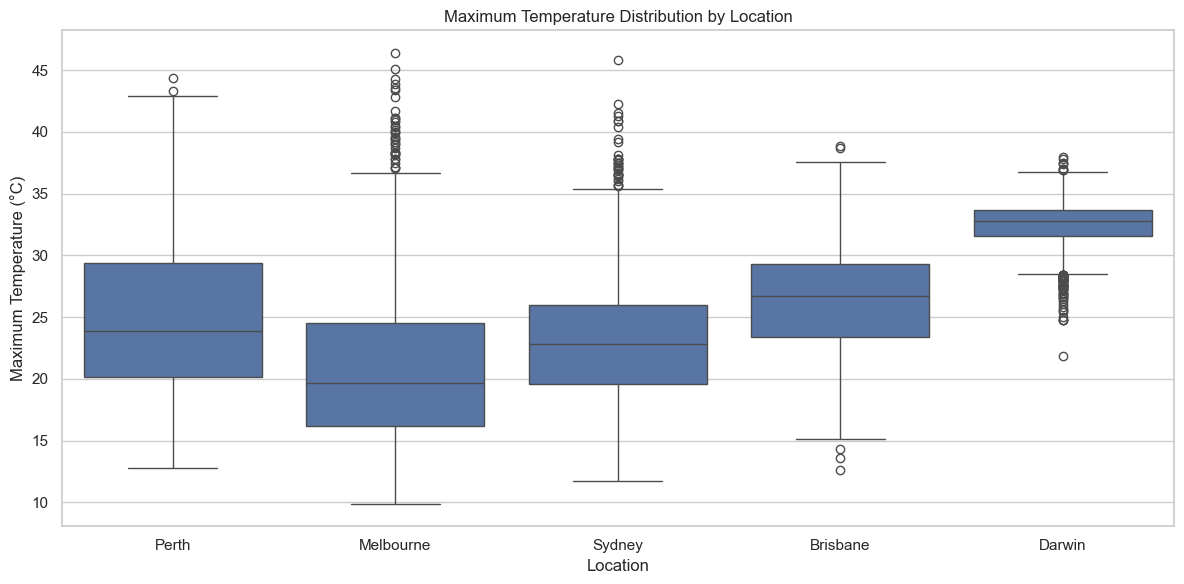

In [69]:
# Five locations
locations = ['Perth','Melbourne','Sydney','Brisbane','Darwin']
df_boxplot = df_features[df_features['Location'].isin(locations)]

# Boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_boxplot, x='Location', y='MaxTemp', order=locations)
plt.title('Maximum Temperature Distribution by Location')
plt.xlabel('Location')
plt.ylabel('Maximum Temperature (°C)')
plt.tight_layout()
plt.show()

**Results:**

- Darwin has the highest median maximum temperature, approximately 33°C, with a relatively narrow distribution.
- Melbourne has the lowest median maximum temperature, approximately 19.5°C, and numerous high-temperature outliers.
- Perth has a median maximum temperature of approximately 24°C and a comparatively wide temperature distribution.
- Sydney contains extreme high-temperature observations exceeding 45°C.
- Brisbane has a median maximum temperature of approximately 27°C, with fewer extreme observations than Melbourne.

**Interpretation:**

The boxplot demonstrates clear differences in temperature distributions between the selected Australian locations.

Darwin experiences consistently high maximum temperatures, while Melbourne and Perth exhibit greater variation in daily maximum temperatures.

The presence of high-temperature outliers in several locations indicates occasional unusually hot days.

Overall, the visualisation highlights geographic differences in temperature patterns and provides a useful comparison of central tendency, variability and extreme observations.

The boxplot summarises the distribution across all available observations but does not directly display the timing or seasonal distribution of those temperatures.

### 7.3 Analysing Monthly Maximum Temperature Patterns

A heatmap was developed to investigate seasonal differences in average maximum temperatures across Perth, Melbourne, Sydney, Brisbane and Darwin.

The Pandas `pivot_table()` function was used to calculate the mean maximum temperature for each combination of location and calendar month.

The resulting table was visualised using Seaborn's `heatmap()` function, with numerical annotations displaying the average temperatures to one decimal place.



## Heatmap — Monthly temperature patterns 


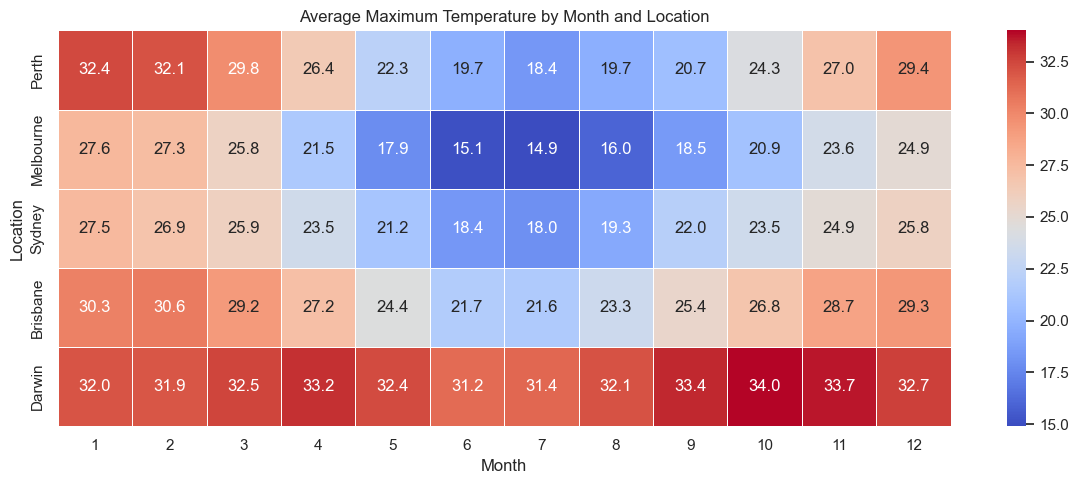

In [70]:
# Average maximum temperature
monthly_temp = df_features.pivot_table( values='MaxTemp', index='Location', columns='Month', aggfunc='mean')

# Five locations
monthly_temp = monthly_temp.loc[locations]

# Heatmap
plt.figure(figsize=(12, 5))
sns.heatmap(monthly_temp, annot=True, fmt='.1f', cmap='coolwarm', linewidths=0.5)
plt.title('Average Maximum Temperature by Month and Location')
plt.xlabel('Month')
plt.ylabel('Location')
plt.tight_layout()
plt.show()

**Results:**

| Location | Warmest Month | Coolest Month |
|---|---|---|
| Perth | January (32.4°C) | July (18.4°C) |
| Melbourne | January (27.6°C) | July (14.9°C) |
| Sydney | January (27.5°C) | July (18.0°C) |
| Brisbane | February (30.6°C) | July (21.6°C) |
| Darwin | October (34.0°C) | June (31.2°C) |

**Interpretation:**

The heatmap demonstrates differences in monthly temperature patterns between the five selected Australian locations.
Perth, Melbourne, Sydney and Brisbane generally experience higher average maximum temperatures during summer and lower temperatures during winter.
Darwin displays a different pattern, maintaining relatively high maximum temperatures throughout the year.
Its warmest month is October, with an average maximum temperature of approximately 34.0°C, while its coolest month is June, averaging approximately 31.2°C.
This indicates a much smaller variation between the warmest and coolest months in Darwin compared with the other four locations.
The results highlight the contrast between tropical and temperate climate patterns within Australia.

**Overall Finding:**

Monthly temperature patterns vary considerably by location. Perth, Melbourne, Sydney and Brisbane exhibit pronounced seasonal differences, whereas Darwin maintains consistently high maximum temperatures throughout the year.
The heatmap provides a clear comparison of monthly averages, although it does not represent year-to-year variability or individual extreme weather events.

### 7.4 Analysing Monthly Maximum Temperature Trends in Perth

A line chart was developed to investigate changes in average maximum temperature in Perth over the available observation period.

The dataset was filtered to include weather observations recorded at Perth. The Date column was then used as the time series index.

The Pandas `resample('MS')` function was applied to group observations by calendar month, using the first day of each month as the corresponding time series label.

The mean maximum temperature was calculated for each monthly period and visualised using Matplotlib.

## Line chart — Perth temperature trends 


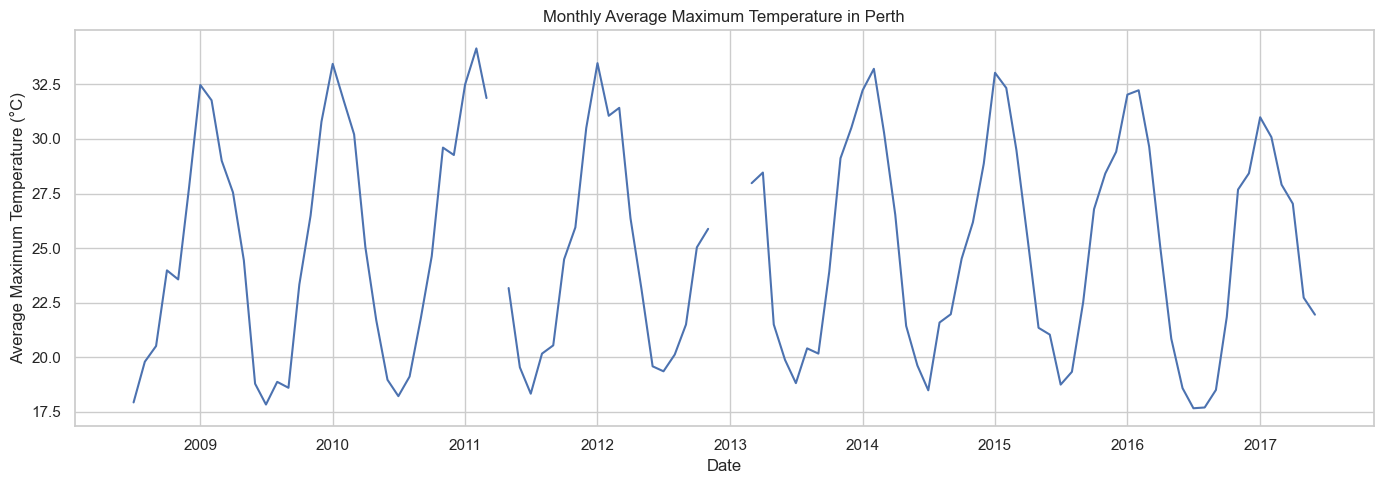

In [71]:
# Perth observations
perth_data = df_features[df_features['Location'] == 'Perth'].copy()
# Group by year and month
perth_monthly = (perth_data.set_index('Date')['MaxTemp'].resample('MS').mean())
# Line chart
plt.figure(figsize=(14, 5))
plt.plot(perth_monthly.index, perth_monthly.values, linewidth=1.5)
plt.title('Monthly Average Maximum Temperature in Perth')
plt.xlabel('Date')
plt.ylabel('Average Maximum Temperature (°C)')
plt.tight_layout()
plt.show()

**Results and Interpretation:**

The line chart demonstrates a repeating annual temperature cycle, with average maximum temperatures generally increasing during summer and decreasing during winter.
This recurring pattern reflects the seasonal variation in Perth's climate.
The chart also contains visible gaps in the time series, which may indicate months without available observations.
Although the visualisation shows short-term fluctuations and repeated seasonal patterns, it does not independently establish a long-term warming or cooling trend.
A more detailed trend analysis would require additional statistical methods and consideration of seasonal effects and observation coverage.

**Overall Finding:**

Perth exhibits a clear seasonal temperature cycle, characterised by warmer summers and cooler winters.

### 7.5 Comparing Average Daily Rainfall Across Australian Cities

A bar chart was created to compare average daily rainfall measurements across five Australian locations: Perth, Melbourne, Sydney, Brisbane and Darwin.

The dataset was filtered to include the selected locations, and the Pandas `groupby()` function was used to calculate the mean recorded rainfall for each location.

The results were arranged in a consistent location order and visualised using Seaborn's `barplot()` function.



## Bar chart — Average daily rainfall ##


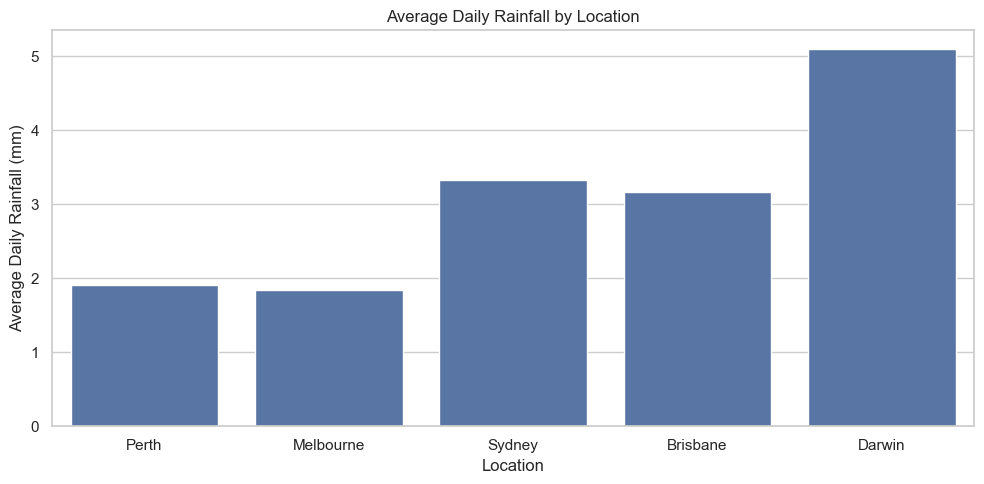

In [72]:
# Average daily rainfall
average_rainfall = (df_features[df_features['Location'].isin(locations)].groupby('Location')['Rainfall'].mean().reindex(locations))

# Bar chart
plt.figure(figsize=(10, 5))
sns.barplot(x=average_rainfall.index, y=average_rainfall.values)
plt.title('Average Daily Rainfall by Location')
plt.xlabel('Location')
plt.ylabel('Average Daily Rainfall (mm)')
plt.tight_layout()
plt.show()

**Results:**

- Darwin recorded the highest average daily rainfall, approximately 5.1 mm.
- Sydney and Brisbane recorded approximately 3.3 mm and 3.2 mm, respectively.
- Perth recorded approximately 1.9 mm.
- Melbourne recorded the lowest average daily rainfall, approximately 1.8 mm.

**Interpretation:**

The results demonstrate substantial differences in average recorded rainfall between the selected locations.

Darwin has the highest average rainfall per observation, while Perth and Melbourne have comparatively lower averages.

These differences are consistent with variations in rainfall characteristics across Australian climate regions.

However, the average rainfall value does not indicate how frequently rainfall occurs or how rainfall is distributed throughout the year.

For example, a location may have a high average rainfall because of occasional heavy rainfall events rather than frequent rainfall.

Differences in observation coverage may also influence the comparison.

**Overall Finding:**

Average daily rainfall varies considerably between Australian locations, with Darwin recording the highest mean rainfall among the five cities examined.

### 7.6 Investigating the Relationship Between Afternoon Temperature and Humidity

A scatterplot was developed to examine the relationship between afternoon temperature and relative humidity.

The analysis used two numerical variables:

- Temp3pm: Temperature recorded at 3 pm, measured in degrees Celsius.
- Humidity3pm: Relative humidity recorded at 3 pm, expressed as a percentage.

A random sample of 5,000 observations was selected from the feature-engineered dataset to improve visual readability and reduce overplotting.

The `random_state=42` parameter was used to ensure that the same observations would be selected when the code was executed again.

Seaborn's `scatterplot()` function was used to display the relationship between the two variables.



## Scatterplot — Temperature versus humidity ##


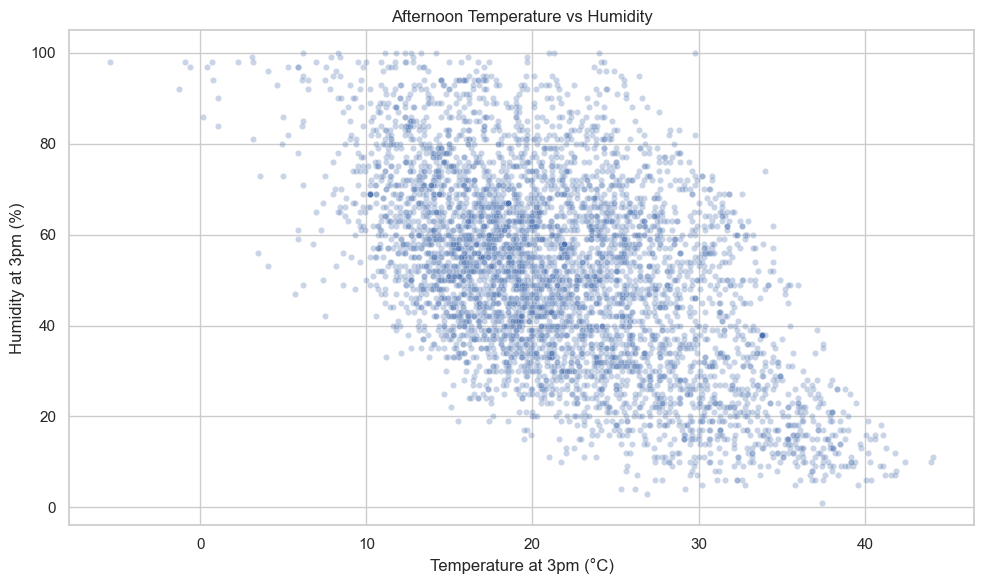

In [73]:
# Reproducible random sample
df_scatter = df_features.sample( n=5000, random_state=42)

# Scatterplot
plt.figure(figsize=(10, 6))
sns.scatterplot( data=df_scatter, x='Temp3pm', y='Humidity3pm', alpha=0.3, s=20)
plt.title('Afternoon Temperature vs Humidity')
plt.xlabel('Temperature at 3pm (°C)')
plt.ylabel('Humidity at 3pm (%)')
plt.tight_layout()
plt.show()

**Results and Interpretation:**

The scatterplot shows a downward relationship between afternoon temperature and relative humidity.

At lower afternoon temperatures, relative humidity values are frequently higher. As afternoon temperatures increase, relative humidity generally decreases.

This observation is consistent with the earlier correlation coefficient of approximately -0.56, indicating a moderate negative linear relationship.

However, considerable variation exists in humidity measurements at similar temperatures, suggesting that additional atmospheric factors influence relative humidity.

The relationship should therefore be interpreted as an association rather than evidence of direct causation.

**Overall Finding:**

Afternoon temperature and relative humidity demonstrate a moderate negative relationship in the analysed weather dataset.

### 7.7 Validating the Data Used for Visualisation

Following the completion of the visualisations, a final verification was performed to confirm the dimensions and completeness of the dataset used for analysis.

The validation examined the total number of observations and variables, remaining missing values, selected locations and scatterplot sample size.

In [74]:
print("Dataset shape:", df_features.shape)
print("Missing values:", df_features.isna().sum().sum())
print("Locations analysed:", locations)
print("Scatterplot sample size:", len(df_scatter))

Dataset shape: (140787, 28)
Missing values: 0
Locations analysed: ['Perth', 'Melbourne', 'Sydney', 'Brisbane', 'Darwin']
Scatterplot sample size: 5000


**Interpretation:**

The results confirm that the feature-engineered dataset contains no missing observations and retains all 140,787 records after the feature engineering process.
The five selected locations were consistently used for the location-based visualisations.
The scatterplot used a reproducible random sample of 5,000 observations to improve readability while retaining a broad representation of the dataset.
These validation checks confirm that the visualisations were generated using the intended data structures and selected observations.
However, the checks do not independently establish that the visualisations are free from sampling bias or that the observed relationships are causal.

## 8. Testing and Validation

### 8.1 Defining a Function for Temperature Range Calculation

Testing and validation are essential components of data analysis because they help identify programming errors, verify expected behaviour and improve the reliability of data-processing operations.

Python's `unittest` framework was selected to perform automated tests on selected functions and dataset properties.

Before implementing unit tests, a function named `calculate_temp_range()` was defined to calculate the difference between maximum and minimum temperatures.

The function accepts two numerical inputs and returns the difference between them.



In [75]:
def calculate_temp_range(max_temp, min_temp):
    return max_temp - min_temp

calculate_temp_range(30, 15)

15

**Results:**

When a maximum temperature of 30°C and a minimum temperature of 15°C were provided, the function returned a temperature range of 15°C.

**Interpretation:**

The result demonstrates that the function performs the intended arithmetic calculation for the example provided.
However, a single example does not establish that the function behaves correctly for all possible inputs.
Therefore, additional unit tests are required to evaluate its behaviour under different temperature conditions.

### 8.2 Unit Testing the Temperature Range Function

Automated unit tests were developed to verify the behaviour of the `calculate_temp_range()` function under different temperature conditions.

Python's built-in `unittest` framework was used to create a test class named `TestTemperatureRange`.

Three test cases were implemented.

**Test 1: Normal Temperature Values**

The function was tested using a maximum temperature of 30°C and a minimum temperature of 15°C.

The expected result was 15°C.

**Test 2: Equal Temperature Values**

The function was tested using identical maximum and minimum temperatures of 20°C.

The expected result was 0°C.

**Test 3: Negative Temperature Values**

The function was tested using a maximum temperature of 5°C and a minimum temperature of -3°C.

The expected result was 8°C.

The `assertEqual()` method was used to compare each calculated result with its expected value.



In [76]:
import unittest

# Function to test
def calculate_temp_range(max_temp, min_temp):
    return max_temp - min_temp


# Create test class
class TestTemperatureRange(unittest.TestCase):

    def test_normal_temperature(self):
        result = calculate_temp_range(30, 15)
        self.assertEqual(result, 15)

    def test_equal_temperatures(self):
        result = calculate_temp_range(20, 20)
        self.assertEqual(result, 0)

    def test_negative_temperatures(self):
        result = calculate_temp_range(5, -3)
        self.assertEqual(result, 8)


# Run tests in Jupyter Notebook
suite = unittest.TestLoader().loadTestsFromTestCase(
    TestTemperatureRange
)

runner = unittest.TextTestRunner(verbosity=2)
runner.run(suite)

test_equal_temperatures (__main__.TestTemperatureRange.test_equal_temperatures) ... ok
test_negative_temperatures (__main__.TestTemperatureRange.test_negative_temperatures) ... ok
test_normal_temperature (__main__.TestTemperatureRange.test_normal_temperature) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.013s

OK


<unittest.runner.TextTestResult run=3 errors=0 failures=0>

**Interpretation:**

The results confirm that the function produces the expected temperature ranges for the three tested scenarios.

The tests demonstrate the use of automated assertions to verify calculations and detect unexpected behaviour.

However, the tests do not cover every possible input, such as non-numerical values or cases where the maximum temperature is lower than the minimum temperature.

Therefore, the successful results provide evidence of correct behaviour for the tested conditions rather than comprehensive validation of every possible input.

### 8.3 Automated Dataset Integrity Testing

In addition to testing individual calculations, automated validation was performed to assess the structural integrity of the cleaned weather dataset.

A test class named `TestDatasetIntegrity` was created using Python's `unittest` framework.

Five test methods were implemented to verify important dataset properties.

**Test 1: Dataset Completeness**

The `test_dataset_not_empty()` method verifies that the cleaned dataset contains at least one observation.

**Test 2: Missing-Value Validation**

The `test_missing_values()` method verifies that the dataset contains zero missing observations.

**Test 3: Duplicate Record Validation**

The `test_duplicate_rows()` method confirms that no fully duplicated records remain.

**Test 4: Unique Date–Location Validation**

The `test_duplicate_date_location()` method verifies that each Date–Location combination occurs only once.

**Test 5: Required Column Validation**

The `test_required_columns()` method checks that the cleaned dataset contains the required variables: Date, Location, MinTemp, MaxTemp, Rainfall and RainTomorrow.

The `assertGreater()`, `assertEqual()` and `assertIn()` methods were used to compare the dataset properties with the expected conditions.



In [77]:
class TestDatasetIntegrity(unittest.TestCase):

    def test_dataset_not_empty(self):
        self.assertGreater(len(df_clean), 0)

    def test_missing_values(self):
        self.assertEqual(
            df_clean.isna().sum().sum(),
            0
        )

    def test_duplicate_rows(self):
        self.assertEqual(
            df_clean.duplicated().sum(),
            0
        )

    def test_duplicate_date_location(self):
        self.assertEqual(
            df_clean.duplicated(
                subset=['Date', 'Location']
            ).sum(),
            0
        )

    def test_required_columns(self):
        required_columns = [
            'Date',
            'Location',
            'MinTemp',
            'MaxTemp',
            'Rainfall',
            'RainTomorrow'
        ]

        for col in required_columns:
            with self.subTest(column=col):
                self.assertIn(col, df_clean.columns)


# Run dataset integrity tests
suite = unittest.TestLoader().loadTestsFromTestCase(
    TestDatasetIntegrity
)

runner = unittest.TextTestRunner(verbosity=2)
runner.run(suite)

test_dataset_not_empty (__main__.TestDatasetIntegrity.test_dataset_not_empty) ... ok
test_duplicate_date_location (__main__.TestDatasetIntegrity.test_duplicate_date_location) ... ok
test_duplicate_rows (__main__.TestDatasetIntegrity.test_duplicate_rows) ... ok
test_missing_values (__main__.TestDatasetIntegrity.test_missing_values) ... ok
test_required_columns (__main__.TestDatasetIntegrity.test_required_columns) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.480s

OK


<unittest.runner.TextTestResult run=5 errors=0 failures=0>

**Results:**

All five test methods passed successfully.
The test runner reported five completed tests, with zero failures and zero errors.

**Interpretation:**

The results provide evidence that the cleaned dataset satisfies the selected structural and completeness requirements.
The absence of missing values and duplicate observations supports the reliability of subsequent data-processing operations.
The required column validation also confirms that the dataset contains the variables needed for the analysis.
However, these tests assess selected dataset properties rather than the physical accuracy of individual weather measurements.
The automated tests provide a repeatable approach to verifying data integrity and can be executed again if the dataset or cleaning procedures are modified.

## 9. Conclusion

This project demonstrated the application of Python for cleaning, processing, transforming, analysing and validating historical Australian weather data.

The original dataset was examined to identify missing observations, categorical inconsistencies, duplicated records and relationships between meteorological variables.

A combination of column removal, selective row removal and location-based statistical imputation was applied to address missing values. The resulting cleaned dataset contained 140,787 observations and 20 variables, with no remaining missing values or duplicated Date–Location records.

Data merging was performed using Pandas to combine temperature, rainfall and atmospheric measurements. The merging process was validated to confirm that all observations and selected measurement values were preserved.

Feature engineering introduced additional date-based and meteorological variables, increasing the number of variables in the analytical dataset to 28. Min-Max normalisation and Z-score standardisation were also demonstrated.

Lambda functions and sorting operations were used to identify high-temperature observations and large daily temperature ranges.

The visualisation stage revealed several important patterns:

- Darwin maintained consistently high maximum temperatures throughout the year.
- Perth, Melbourne, Sydney and Brisbane displayed more pronounced seasonal temperature differences.
- Darwin recorded the highest average daily rainfall among the five selected locations.
- Afternoon temperature and relative humidity demonstrated a moderate negative relationship.
- Perth exhibited a recurring annual temperature cycle.

Finally, automated unit testing and dataset integrity checks were implemented using Python's `unittest` framework. All eight saved tests passed, with zero failures and zero errors.

### 9.1 Limitations

Several limitations should be acknowledged.

The removal of highly incomplete variables reduced the information available for analysis. Additionally, statistical imputation introduced estimated values that may not fully represent actual weather conditions.

Differences in observation coverage between locations may influence geographic comparisons.

The visualisations primarily demonstrate descriptive relationships and do not establish causal relationships between meteorological variables.

### 9.2 Future Improvements

Future analysis could investigate alternative imputation techniques, seasonal rainfall distributions and long-term temperature trends.

Additional statistical methods could also be used to examine relationships between meteorological variables.

Predictive modelling could be explored using appropriate training and testing procedures, with particular attention to class imbalance, feature selection and prevention of data leakage.

Overall, the project demonstrates a structured and reproducible approach to weather data analysis using Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn and automated testing.

In [78]:
import unittest
import pandas as pd

class TestDataMerging(unittest.TestCase):

    # Test 1: Verify row counts
    def test_row_count(self):
        self.assertEqual(
            len(df_merged),
            len(df_clean)
        )

    # Test 2: Verify duplicate merging keys
    def test_duplicate_keys(self):
        duplicates = df_merged.duplicated(
            subset=['Date', 'Location']
        ).sum()

        self.assertEqual(duplicates, 0)

    # Test 3: Verify missing values
    def test_missing_values(self):
        missing = df_merged.isna().sum().sum()

        self.assertEqual(missing, 0)

    # Test 4: Verify required columns
    def test_required_columns(self):
        required_columns = [
            'Date',
            'Location',
            'MinTemp',
            'MaxTemp',
            'WindGustSpeed',
            'Humidity9am',
            'Pressure9am'
        ]

        for col in required_columns:
            with self.subTest(column=col):
                self.assertIn(col, df_merged.columns)

    # Test 5: Verify merged values match original data
    def test_merged_data_accuracy(self):

        columns = df_merged.columns.tolist()

        original = (
            df_clean[columns]
            .sort_values(['Date', 'Location'])
            .reset_index(drop=True)
        )

        merged = (
            df_merged
            .sort_values(['Date', 'Location'])
            .reset_index(drop=True)
        )

        pd.testing.assert_frame_equal(
            original,
            merged
        )


# Run tests
suite = unittest.TestLoader().loadTestsFromTestCase(
    TestDataMerging
)

runner = unittest.TextTestRunner(verbosity=2)
result = runner.run(suite)

test_duplicate_keys (__main__.TestDataMerging.test_duplicate_keys) ... ok
test_merged_data_accuracy (__main__.TestDataMerging.test_merged_data_accuracy) ... ok
test_missing_values (__main__.TestDataMerging.test_missing_values) ... ok
test_required_columns (__main__.TestDataMerging.test_required_columns) ... ok
test_row_count (__main__.TestDataMerging.test_row_count) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.860s

OK
